In [1]:
import pandas as pd
import numpy as np

from ArtPaths_slim import stats_condition

from IPython.display import clear_output

/its/home/nn268/.local/lib/python3.10/site-packages/pandas/core/arrays/masked.py:62: UserWarning: Pandas requires version '1.3.4' or newer of 'bottleneck' (version '1.3.2' currently installed).
  from pandas.core import (
/its/home/nn268/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [2]:
antTrackDF = pd.read_csv("AbbottsWoodsCombinedTidy.csv")

antTrackDF['ID'] = antTrackDF.ID.astype(str)

antTrackDF['Condition'] = antTrackDF['Condition'].astype('str')

/tmp/ipykernel_196726/4226402365.py:1: DtypeWarning: Columns (2,8,9) have mixed types. Specify dtype option on import or set low_memory=False.
  antTrackDF = pd.read_csv("AbbottsWoodsCombinedTidy.csv")


In [3]:
print(np.unique(antTrackDF['Condition']))

['Minus 3m ZV' 'Off-route 1 ZV' 'On-route 1 ZV' 'On-route 1B ZV'
 'On-route 2 ZV' 'Plus 3m ZV' 'Route 0m ZV' 'Unfamiliar FV'
 'Unfamiliar ZV' 'Unfamiliar ZV 2' 'Unfamiliar ZV 3']


In [4]:
antTrackDF_offr1zv = antTrackDF[antTrackDF['Condition']=='Off-route 1 ZV']

antTrackDF_offr1zv_num = antTrackDF[antTrackDF['ID'].astype('str') == '696']
print(antTrackDF_offr1zv_num)

        Unnamed: 0    Date   ID  frame           x          y     Nest  \
926959      926959  Aug-28  696      0   17.476185  70.419554  NewNest   
926960      926960  Aug-28  696      1   16.972360  71.348381  NewNest   
926961      926961  Aug-28  696      2   16.375291  72.246648  NewNest   
926962      926962  Aug-28  696      3   15.418013  73.699628  NewNest   
926963      926963  Aug-28  696      4   14.892981  74.734352  NewNest   
...            ...     ...  ...    ...         ...        ...      ...   
927917      927917  Aug-28  696    960 -288.293311  82.591863  NewNest   
927918      927918  Aug-28  696    961 -288.297921  82.662674  NewNest   
927919      927919  Aug-28  696    962 -288.232028  82.612474  NewNest   
927920      927920  Aug-28  696    963 -288.344001  82.678844  NewNest   
927921      927921  Aug-28  696    964 -288.318107  82.640678  NewNest   

             Condition Sector Direction  
926959  Off-route 1 ZV    2.0      22.5  
926960  Off-route 1 ZV    2

In [5]:
antTrackDF_unf2 = antTrackDF[antTrackDF['Condition']=='Unfamiliar ZV 2']

print(len(np.unique(antTrackDF_unf2['ID'].astype('str'))))

antTrackDF_unf3 = antTrackDF[antTrackDF['Condition']=='Unfamiliar ZV 3']

print(len(np.unique(antTrackDF_unf3['ID'].astype('str'))))

61
62


In [6]:
antTrackDF_nan = antTrackDF[antTrackDF['Condition']=='nan']

print(antTrackDF_nan)

Empty DataFrame
Columns: [Unnamed: 0, Date, ID, frame, x, y, Nest, Condition, Sector, Direction]
Index: []


In [10]:


usedf = antTrackDF.copy()

"""

StraightnessIndex
FrameHeadingsNoGaps2_CircR
StraightnChunksCircR
SpeedPerFrameNoGapsMean
FinalPointRelToNest
LengthTotalCm
BeelinePath (cm)
"""


#dict = {"Nest": [], "Condition": [],"Ant ID": [], "finalhead29": [],"finalhead29rel2Nest":[],"Straightness_Index": [],
#        "trim_CircR_chunked": [], "trimChunk_CircR": [], "TrimspeedPerFramemean" :[]}
dict = {"Nest": [], "Condition": [],"Ant ID": [], "TrimStraightnessIndex": [], "TrimNoGaps_CircR": [], "TrimChunksCircR":[], "TrimSpeedPerFrameNoGapsMean":[],
       "TrimFinalPointRelToNest":[], "TrimLengthTotalmm":[], "TrimBeelinePath (mm)":[]}

allTrimdata =  pd.DataFrame({'A':[]})
allTrimdata = allTrimdata.drop('A', axis = 1)
allTrimNGdata =  pd.DataFrame({'A':[]})
allTrimNGdata = allTrimNGdata.drop('A', axis = 1)

allFPdata =  pd.DataFrame({'A':[]})
allFPdata = allFPdata.drop('A', axis = 1)

wig_uniqconds = np.unique(usedf[usedf['Nest']=="Wigwam"]['Condition']) # All conditions
#wig_uniqconds = ['On-route 1 ZV'] # specify condition
print(f"Wig conds {wig_uniqconds}")

nn_uniqconds =  np.unique(usedf[usedf['Nest']=="NewNest"]['Condition'])  # All conditions
#nn_uniqconds = ['Off-route 1 ZV']#['On-route 1 ZV']  # specify condition
print(f"NN conds {nn_uniqconds}")
#unique_conditions = np.unique(usedf['Condition'])

# unique_nests = np.unique(usedf['Nest']) # All nests
unique_nests = ['Wigwam','NewNest'] # specify nest  NewNest ,'''Wigwam',
outdf = pd.DataFrame({'A' : [np.nan]})
outdf.dropna().empty
for nest in unique_nests:
    if nest ==  "Wigwam":
        unique_conditions = wig_uniqconds
    elif nest == "NewNest":
        unique_conditions = nn_uniqconds
    ndist_list = []
    nspeed_list = []
    
    nstraight_list = []
    print('----    ------')
    print(nest)
    for condition in unique_conditions:
        dataframe = pd.DataFrame.from_dict(dict, orient = 'columns')
        cond=condition
        print(nest, condition)

        outdf_FP, outdf_Trim, outdf_TNG, fpchunkDict, trimchunkDict, trimNGchunkDict  = stats_condition(usedf, nest=nest, condition=condition, pplot=False,all=True)
        #print("Trim")
        #clear_output()
        #outdf_Trim.to_csv("TrimWigwam.csv")

        #outdf_TNG.to_csv("TrimNGWigwam.csv")


        #print(f"trim wig 863  ", len(outdf_Trim[outdf_Trim['ID']=='286']))
        #print(f"trim NG wig 863  ", len(outdf_TNG[outdf_TNG['ID']=='286']))
        #print(outdf_Trim)
        #print(F"FP {outdf_FP}")
        #print(list(fpchunkDict))
        #print(list(trimchunkDict))
        #print(list(trimNGchunkDict))
        ids = np.unique(outdf_FP['ID'].astype(str))
        for idx, i in enumerate(ids): # np.unique(trimchunkDict['ID'].astype(str))
            print(f"Ant {i}")
            print(list(trimchunkDict))
            trimchunkdf =  trimchunkDict[trimchunkDict['ID']== i]
            trimdf = outdf_Trim[outdf_Trim['ID']==i]
            trimNGdf = outdf_TNG[outdf_TNG['ID']==i]
            
            if len(trimchunkdf) >1 and len(trimdf) >1:
                #newrow = {"Nest": [nest], "Condition": [condition],"Ant ID": [i], "finalhead29": [np.array(trimdf['theta'])[-1]],
                #"finalhead29rel2Nest":[np.array(trimdf['thetaR2N'])[-1]], "Straightness_Index" : [np.array(trimdf['trim_StraightnessIDX'])[-1]],
                #"trim_CircR_chunked" : [np.array(trimdf['trim_circR'])[-1]], "trimChunk_CircR": [np.array(trimchunkdf['trimChunkCIRCR'])[-1]],
                #"TrimspeedPerFramemean": [np.array(trimdf['meanSpeed'])[-1]]}
                newrow = {"Nest": [nest], "Condition": [condition],"Ant ID": [i], "TrimStraightnessIndex": [np.array(trimdf['trim_StraightnessIDX'])[-1]],
                          "TrimNoGaps_CircR": [np.array(trimNGdf['trimNG_circR'])[-1]], "TrimChunksCircR":[np.array(trimchunkdf['trimChunkCIRCR'])[-1]],
                          "TrimSpeedPerFrameNoGapsMean":[np.array(trimNGdf['meanSpeed'])[-1]], "TrimFinalPointRelToNest":[np.array(trimdf['thetaR2N'])[-1]],
                          "TrimLengthTotalmm":[np.array(trimdf['accumDist'])[-1]], "TrimBeelinePath (mm)":[np.array(trimdf['trim_beeline'])[-1]]}
            else:
                #newrow = {"Nest": [nest], "Condition": [condition],"Ant ID": [i], "finalhead29": [np.nan],"finalhead29rel2Nest":[np.nan],
                #          "Straightness_Index" : [np.nan], "trim_CircR_chunked" : [np.nan],
                #          "trimChunk_CircR": [np.nan], "TrimspeedPerFramemean": [np.nan]}
                newrow = {"Nest": [nest], "Condition": [condition],"Ant ID": [i], "TrimStraightnessIndex":[np.nan], "TrimNoGaps_CircR": [np.nan], "TrimChunksCircR": [np.nan],
                         "TrimSpeedPerFrameNoGapsMean":[np.nan], "TrimFinalPointRelToNest":[np.nan], "TrimLengthTotalmm" :[np.nan], "TrimBeelinePath (mm)" :[np.nan]}
            dataframe = pd.concat([dataframe, pd.DataFrame(newrow)], ignore_index=True)
        dataframe.to_csv(f"{nest}_{cond}.csv")
        allTrimdata = pd.concat([allTrimdata, outdf_Trim], ignore_index=True)
        allTrimNGdata = pd.concat([allTrimNGdata, outdf_TNG], ignore_index=True)
        allFPdata = pd.concat([allFPdata, outdf_FP], ignore_index=True)
        #clear_output()
            
"""if len(trimchunkDict) >1 and len(outdf_Trim) >1:
    print("df > 1")
    newrow = {"Nest": [nest], "Condition": [condition],"Ant ID": np.unique(np.array(outdf_Trim['ID'].astype(str))),
              "finalhead29": [np.array(outdf_Trim['theta'])[-1]], "finalhead29rel2Nest":[np.array(outdf_Trim['thetaR2N'])[-1]],
              "Straightness_Index" : [np.array(outdf_Trim['trim_StraightnessIDX'])[-1]],
              "trim_CircR_chunked" : [np.array(outdf_Trim['trim_circR'])[-1]], "trimChunk_CircR": [np.array(trimchunkDict['trimChunkCIRCR'])[-1]],
              "TrimspeedPerFramemean": [np.array(outdf_Trim['meanSpeed'])[-1]]}
    #dataframe = pd.concat([dataframe, pd.DataFrame(newrow)], ignore_index=True)
    dataframe.update(newrow, join='left')
else:
    print("df < 1")
    newrow = {"Nest": [nest], "Condition": [condition],"Ant ID": [i], "finalhead29": [np.nan],"finalhead29rel2Nest":[np.nan],
              "Straightness_Index" : [np.nan], "trim_CircR_chunked" : [np.nan],
              "trimChunk_CircR": [np.nan], "TrimspeedPerFramemean": [np.nan]}
    dataframe = pd.concat([dataframe, pd.DataFrame(newrow)], ignore_index=True)"""
#dataframe = pd.concat([dataframe, pd.DataFrame(newrow)], ignore_index=True)
#dataframe.
#print(outdf)


            





Wig conds ['Off-route 1 ZV' 'On-route 1 ZV' 'On-route 2 ZV' 'Unfamiliar FV'
 'Unfamiliar ZV']
NN conds ['Minus 3m ZV' 'Off-route 1 ZV' 'On-route 1 ZV' 'On-route 1B ZV'
 'On-route 2 ZV' 'Plus 3m ZV' 'Route 0m ZV' 'Unfamiliar FV'
 'Unfamiliar ZV' 'Unfamiliar ZV 2' 'Unfamiliar ZV 3']
----    ------
Wigwam
Wigwam Off-route 1 ZV
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
Ant 270
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 271
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 272
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 273A
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 273B
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 274
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 275
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 276
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 277
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 278
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX'

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
Ant 283
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 285
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 286
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 287
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 288
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 289
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 290
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 291
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 292
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim
else trim
Ant 298
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 299
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 300
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 301
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 303
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 304
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 305
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 307
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 309
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 334
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChu

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
Ant 364
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 365
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 366
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 367
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 368
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 369
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 370
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 371
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 372
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 373
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
Ant 310
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 311
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 312
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 313
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 314
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 315
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 318
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 319
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 321
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 322
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 323
['ID', 'Trim

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
Ant 108
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 109
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 110
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 111
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 120
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 121
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 122
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 123
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 132
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 133
['ID', 'TrimchunkTheta', 'tri

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:221: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_circR'] = new_circR(np.array(fpf1['dTheta']))
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:224: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['trimNG_circR'] = new_circR(np.array(trimf1['dTheta'])[1:])
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
Ant 561
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 562
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 563
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 564
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 565
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 566
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 579
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 580
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 581
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 582
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 583
['

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
Ant 552
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 553
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 554
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 556
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 557
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 558
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 573
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 574
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 575
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 576
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:221: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_circR'] = new_circR(np.array(fpf1['dTheta']))
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value 

else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
Ant 882
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 883
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 884
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 885
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 886
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 887
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 888
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 889
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 890
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 891
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 892
['ID', 'Trim

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
Ant 567
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 568
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 569
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 570
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 571
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 572
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 595
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 596
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 597
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 598
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 599
['

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
Ant 116
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 117
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 118
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 119
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 128
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 129
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 130
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 131
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 142
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 143
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 173
['ID', 'Trim

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
Ant 112
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 113
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 114
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 115
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 124
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 125
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 126
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 127
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 136
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 137
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:224: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['trimNG_circR'] = new_circR(np.array(trimf1['dTheta'])[1:])
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning:

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
Ant 810
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 811
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 812
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 813
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 814
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 815
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 816
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 817
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 818
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 819
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
Ant 642
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 643
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 644
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 645
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 646
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 647
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 648
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 649
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 650
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 651
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 652
['ID', 'Trim

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
Ant 24
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 25
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 26
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 27
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 28
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 29
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 30
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 31
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 32
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 33
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 34
['ID', 'TrimchunkTheta'

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:214: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['trimNG_StraightnessIDX'], trimf1['trimNG_beeline'] = StraightnessIndex(np.array(trimf1['accumDist']),#[:-1], #*#
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:214: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['trimNG_StraightnessIDX'], trimf1['trimNG_beeline'] = StraightnessIndex(np.array(trimf1['accumDist']),#[:-1], #*#
/its/home/nn268/antvis/antvis/

else trim
else trim
else trim
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

else trim
else trim
Ant 1
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 11
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 12
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 13
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 14
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 15
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 16
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 17
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 18
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 19
['ID', 'TrimchunkTheta', 'trimchunkR', 'headings', 'trimChunkCIRCR', 'chunkX', 'chunkY']
Ant 2
['ID', 'Trimchu

'if len(trimchunkDict) >1 and len(outdf_Trim) >1:\n    print("df > 1")\n    newrow = {"Nest": [nest], "Condition": [condition],"Ant ID": np.unique(np.array(outdf_Trim[\'ID\'].astype(str))),\n              "finalhead29": [np.array(outdf_Trim[\'theta\'])[-1]], "finalhead29rel2Nest":[np.array(outdf_Trim[\'thetaR2N\'])[-1]],\n              "Straightness_Index" : [np.array(outdf_Trim[\'trim_StraightnessIDX\'])[-1]],\n              "trim_CircR_chunked" : [np.array(outdf_Trim[\'trim_circR\'])[-1]], "trimChunk_CircR": [np.array(trimchunkDict[\'trimChunkCIRCR\'])[-1]],\n              "TrimspeedPerFramemean": [np.array(outdf_Trim[\'meanSpeed\'])[-1]]}\n    #dataframe = pd.concat([dataframe, pd.DataFrame(newrow)], ignore_index=True)\n    dataframe.update(newrow, join=\'left\')\nelse:\n    print("df < 1")\n    newrow = {"Nest": [nest], "Condition": [condition],"Ant ID": [i], "finalhead29": [np.nan],"finalhead29rel2Nest":[np.nan],\n              "Straightness_Index" : [np.nan], "trim_CircR_chunked"

In [8]:
print(allTrimdata)
allTrimdata.to_csv("RealAnts_ALL_TRIM.csv")

             index  Unnamed: 0    Date   ID   frame          x           y  \
0              NaN         NaN     NaN  NaN     NaN        NaN         NaN   
1          49819.0     49819.0  Jul-18  270    58.0  11.997331  -28.174440   
2          49820.0     49820.0  Jul-18  270    59.0  11.627024  -29.415378   
3          49821.0     49821.0  Jul-18  270    60.0  10.589183  -30.483587   
4          49822.0     49822.0  Jul-18  270    61.0   9.926576  -31.682379   
...            ...         ...     ...  ...     ...        ...         ...   
2609116  1760357.0   1760357.0  Sep-10  999  4324.0  -4.893757  230.402216   
2609117  1760358.0   1760358.0  Sep-10  999  4325.0  -4.408389  230.750098   
2609118  1760359.0   1760359.0  Sep-10  999  4326.0  -3.940715  231.474228   
2609119  1760360.0   1760360.0  Sep-10  999  4327.0  -3.611261  232.192958   
2609120  1760361.0   1760361.0  Sep-10  999  4337.0  -2.093127  235.396267   

            Nest        Condition Sector  ... deltaDist   accum

In [9]:
print(allTrimNGdata)
allTrimNGdata.to_csv("RealAnts_ALL_TRIMNG.csv")

             index  Unnamed: 0    Date   ID   frame          x           y  \
0              NaN         NaN     NaN  NaN     NaN        NaN         NaN   
1          49819.0     49819.0  Jul-18  270    58.0  11.997331  -28.174440   
2          49820.0     49820.0  Jul-18  270    59.0  11.627024  -29.415378   
3          49821.0     49821.0  Jul-18  270    60.0  10.589183  -30.483587   
4          49822.0     49822.0  Jul-18  270    61.0   9.926576  -31.682379   
...            ...         ...     ...  ...     ...        ...         ...   
2595239  1760356.0   1760356.0  Sep-10  999  4323.0  -4.899817  230.040660   
2595240  1760357.0   1760357.0  Sep-10  999  4324.0  -4.893757  230.402216   
2595241  1760358.0   1760358.0  Sep-10  999  4325.0  -4.408389  230.750098   
2595242  1760359.0   1760359.0  Sep-10  999  4326.0  -3.940715  231.474228   
2595243  1760360.0   1760360.0  Sep-10  999  4327.0  -3.611261  232.192958   

            Nest        Condition Sector  ... deltaDist   accum

In [10]:
#dataframe.to_csv(f"{nest}_{cond}.csv")

In [11]:
hold up

SyntaxError: invalid syntax (1930544515.py, line 1)

NewNest Off-route 1 ZV
561   dtheta in f1   [       nan 2.75700605 2.53908039 ... 1.4460401  2.11010021 0.08599933]
561  b4 circr   ALL: [       nan 2.75700605 2.53908039 ... 1.4460401  2.11010021 0.08599933]    [1:] :[ 2.75700605  2.53908039 -2.90562067 ...  1.4460401   2.11010021
  0.08599933] 
561 x:  [[ -18.50568599  -35.83819118  -41.77170735  -53.17918477  -43.05225117
   -32.61388183  -25.94133811  -35.94821725  -54.90368003  -73.94866585
   -93.02096867 -109.80598927 -124.32650164 -138.74801799 -156.23379734
  -173.48481451 -193.20363418 -212.40746704 -232.09827823 -246.1323069
  -270.46794739]] y: [[ 24.67045884  22.95097596   5.18753592  -1.46463073   1.57781011
   16.76449246  35.21865211  41.07930161  35.69543931  31.64388005
   25.52756135  18.5906308    5.85921885  -3.61513881 -10.95548217
  -17.30860171 -17.85906728 -15.66165206 -14.80269266  -9.12074682
    2.82361314]]
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

562   dtheta in f1   [-1.55589239 -0.81221376 -1.71023404 ...  1.35241982  1.02121011
  0.70416337]
562  b4 circr   ALL: [-1.55589239 -0.81221376 -1.71023404 ...  1.35241982  1.02121011
  0.70416337]    [1:] :[-0.81221376 -1.71023404 -0.8223855  ...  1.35241982  1.02121011
  0.70416337] 
562 x:  [[ 6.50849024e-03 -4.12539902e+00 -6.85573627e+00 -2.04575630e+01
  -3.07610679e+01 -3.85711718e+01 -5.14265624e+01 -4.83102210e+01
  -3.04322089e+01 -1.24013528e+01  5.26431708e+00  1.66487863e+01
   1.54480552e+01  3.97269045e+00 -1.33195521e+01 -2.26036021e+01
  -1.81622810e+01 -9.17497205e+00 -7.51719156e+00 -4.71163567e+00
   7.71249520e+00  2.51580089e+01  4.34811507e+01  6.13694507e+01
   7.99233270e+01  9.92479363e+01  1.16827480e+02  1.31707650e+02
   1.39941818e+02  1.48711065e+02  1.53095927e+02  1.44915182e+02
   1.32110916e+02  1.20436118e+02  1.13238190e+02  1.07652760e+02
   1.09902181e+02  1.12979836e+02]] y: [[ 45.52306009  64.19530566  80.1234519   80.12847044  62.99194571
   

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

563   dtheta in f1   [        nan -3.04314932  2.60241456 ...  0.06337485 -2.30024578
 -0.88493156]
563  b4 circr   ALL: [        nan -3.04314932  2.60241456 ...  0.06337485 -2.30024578
 -0.88493156]    [1:] :[-3.04314932  2.60241456 -2.37536306 ...  0.06337485 -2.30024578
 -0.88493156] 
563 x:  [[-3.83159070e-01  8.49688551e+00  1.36563306e+01 -3.08565390e+00
  -4.26650438e+00 -1.89114938e+00 -3.02746950e+00  1.32602761e+01
   9.54860231e+00 -6.38354748e+00 -1.20614294e+01 -1.79809088e+01
  -3.05547766e+01 -1.55458154e+01  2.81104555e+00  2.04165434e+01
   1.80206145e+01  8.53150794e+00 -5.10693533e+00 -2.05094040e+01
  -4.02613331e+01 -5.98287863e+01 -6.98019463e+01 -6.67293827e+01
  -5.26458849e+01 -3.69017900e+01 -1.72231862e+01 -9.89828766e-01
  -2.87492317e+00 -1.72997254e+01 -3.71713598e+00  1.45172128e+01
   1.46091394e+01  8.01646471e+00 -8.02424631e-01 -1.06291309e+01
  -2.29142445e+01 -3.88110540e+01 -5.84666935e+01 -7.74680967e+01
  -9.44890308e+01 -1.10482540e+02 -1.240014

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

564   dtheta in f1   [        nan -2.87608606 -2.35029928 ... -0.40262376  0.65004952
  0.68407912]
564  b4 circr   ALL: [        nan -2.87608606 -2.35029928 ... -0.40262376  0.65004952
  0.68407912]    [1:] :[-2.87608606 -2.35029928  2.46140328 ... -0.40262376  0.65004952
  0.68407912] 
564 x:  [[-29.68622478 -43.33518106 -33.36241802 -13.92720275   3.22783953
    3.3963829    0.2918126   -7.35063321 -23.23747989 -40.47019619
  -56.32201625 -69.85339956 -82.15209878 -89.82525227 -85.37458892
  -82.2695004  -70.7111041  -56.32348975 -40.1030878  -21.60511237
   -2.33171282  19.35297985  37.95004628  58.01659038  75.98845174
   96.72899239 115.27021964 130.53177721 138.11575376 138.39733534
  137.4916296  138.14514515 135.90740785 133.70118349 126.54655269
  115.69955143 102.14069739  97.42139613  89.18372023  75.53657898
   60.49197723  44.26674084  30.98646615  18.22452595   1.13490404
  -16.75843647 -24.07028081 -27.83838423 -14.01915139   1.29989508
   14.00024169  25.74436481  38.0

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

565   dtheta in f1   [            nan -2.26945362e+00 -2.13818544e+00 -1.84244935e+00
 -1.75593379e+00 -1.78112792e+00 -2.04326428e+00 -1.81721468e+00
 -2.52527220e+00 -2.37857146e+00 -2.44738306e+00 -2.01352190e+00
 -2.10053479e+00 -1.60625579e+00 -1.61661507e+00 -2.22473018e+00
 -2.43781955e+00 -2.32761699e+00 -2.07801691e+00 -2.33565415e+00
 -1.92485577e+00 -1.91917581e+00 -1.39962280e+00 -1.59694316e+00
 -1.85691235e+00 -1.89816814e+00 -1.78695490e+00 -1.99227250e+00
 -1.72423794e+00 -1.72500407e+00 -1.56051887e+00 -1.78742197e+00
 -1.79342546e+00 -1.79997535e+00 -1.63457561e+00 -1.84277450e+00
 -2.03690778e+00 -1.36829942e+00 -1.29352225e+00 -1.11335891e+00
 -1.32493133e+00 -1.38683742e+00 -2.33006682e+00 -1.99880589e+00
 -1.79463941e+00 -1.81827037e+00 -1.83208114e+00 -1.58518107e+00
 -1.27108714e+00 -1.96224150e+00 -1.84142948e+00 -2.07661740e+00
 -1.94399137e+00 -1.92814018e+00 -1.77871136e+00 -2.00813185e+00
 -1.69164387e+00 -1.54226629e+00 -1.91012451e+00 -1.97413515e+00
 -2.

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

566   dtheta in f1   [        nan -0.67297636 -0.50096841 ...  0.89459452  0.35387186
  1.05317895]
566  b4 circr   ALL: [        nan -0.67297636 -0.50096841 ...  0.89459452  0.35387186
  1.05317895]    [1:] :[-0.67297636 -0.50096841 -0.44238883 ...  0.89459452  0.35387186
  1.05317895] 
566 x:  [[  3.57410612  20.07232831  26.10629925  16.51752443  -0.40667315
  -19.25972633  -7.53498368  -3.22478431  -8.58343313   1.86897492
    7.84729169   5.03391358  18.31366585  34.72808811  45.19278604
   51.35380936  58.48828042  64.77420317  55.59183358  49.09013499
   45.74194885  29.7910869   10.26500786  -5.98327213 -24.62675991
  -11.69388473   6.38243981  23.86590805  34.19719032  20.80163088
    3.53823447 -14.91759346 -31.20271318 -47.62160636 -39.722488
  -25.65278057 -21.63714977 -22.0170876  -26.71842029 -19.57677361
  -29.07106014 -32.3057979  -42.32220962 -57.95166607 -67.25383514
  -50.70543889 -35.82853518 -18.35422153  -0.26745645  18.94977195
   42.28065894  68.22312761  92.977

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

579   dtheta in f1   [            nan -1.22176312e+00 -1.95305577e+00 -2.89160935e+00
 -2.55509507e+00 -2.26915433e+00 -2.17510005e+00 -2.13167879e+00
 -1.93119905e+00 -1.62179573e+00 -7.74925195e-01 -1.45575321e+00
 -1.82171641e+00 -2.53761300e+00 -1.35207397e+00 -1.89127692e+00
 -1.52965913e+00 -1.56081724e+00 -1.43613906e+00 -1.11480344e+00
 -1.06849134e+00 -1.13173418e+00 -1.63107890e+00 -1.45014616e+00
 -1.38084477e+00 -1.54675578e+00 -1.26282717e+00 -1.38209911e+00
 -1.27152504e+00 -1.00544785e+00 -1.86360145e+00 -2.03091310e+00
 -1.82139243e+00 -1.39474269e+00 -1.42512317e+00 -8.39988736e-01
 -1.23370210e+00 -1.33693716e+00 -1.48888157e+00 -1.17338546e+00
 -1.36065816e+00 -1.35785863e+00 -1.60633025e+00 -1.28914052e+00
 -9.61654437e-01 -1.01895226e+00 -1.23105944e+00 -1.31756739e+00
 -1.99985070e+00 -1.72548505e+00 -1.43249544e+00 -1.54423840e+00
 -1.11007410e+00 -1.04555000e+00 -1.21260601e+00 -1.56101427e+00
 -1.98238748e+00 -1.63687902e+00 -1.76827704e+00 -1.54546877e+00
 -1.

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

580   dtheta in f1   [-1.75829079  0.31286035  0.06046028  0.45524736  0.30871318  0.39818729
  0.48541874  0.66884032  0.62616284  0.27252569  1.36789473  0.78591224
  0.99640546  0.97485398  0.76007907  0.69991635  2.31641988  1.71846889
  2.22534632  1.61988492  1.42571164  1.97269028 -0.1141164   1.82678051
  1.67195141  1.89054445  1.39738725  1.6011423   2.29532115  2.07209001
 -2.93207868  1.97851112 -2.86117143  2.30153122  1.72112973  0.05152748
 -0.86954121 -1.32802552  2.23362684  3.02420619 -1.4255374  -0.91160258
 -0.7400351  -0.54716022  2.90860209 -2.58060101 -0.78293801  1.89837128
 -3.13893587  2.52494082 -2.9537874   2.82660373 -2.42497986 -2.98665342
  2.77938826  2.49104456  2.84508199 -3.13821111 -2.94002825 -2.83365326
  2.82563105  2.77122292  2.7607643  -3.01638293 -2.70765554 -2.79981472
 -2.98816345 -3.0660969  -2.79810316 -2.39743459 -2.17784235 -1.85670632
 -2.08625848 -2.28522798 -2.43743899 -2.26921997 -1.59320826 -2.18785509
 -2.49261928 -2.19881025 -1.84

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

581   dtheta in f1   [-1.01739592 -2.80974886 -2.55793225 ...  0.89133011 -1.80769892
 -1.69737362]
581  b4 circr   ALL: [-1.01739592 -2.80974886 -2.55793225 ...  0.89133011 -1.80769892
 -1.69737362]    [1:] :[-2.80974886 -2.55793225  1.50897564 ...  0.89133011 -1.80769892
 -1.69737362] 
581 x:  [[  73.88860381   88.26950382  106.05913893  104.47799494  105.6215774
   101.26268504  100.91661568  108.66447468   99.30919623   81.72292871
    63.45086196   56.56793751   38.06429163   21.68114337    5.24724325
     4.5618397    11.80985801   22.94477106   21.77810694   24.5150025
    21.07936969    3.69384849  -14.10712641  -27.42796225  -43.15966203
   -59.92565974  -72.64593305  -72.00598524  -89.6395353  -104.85986675
   -92.41587112  -69.05594675  -50.42784251  -35.5498635   -24.38077518
    -5.46406575    5.75800955    5.02506006    5.63542558    6.64350066
     0.78224894   -0.81507686    9.54188842    7.7933393    -3.1206235
    -5.9534075     2.59469339   -6.61046223]] y: [[   7.01

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

582   dtheta in f1   [        nan  1.13811977  0.68905426 ...  2.70245882  2.7567755
 -2.37401372]
582  b4 circr   ALL: [        nan  1.13811977  0.68905426 ...  2.70245882  2.7567755
 -2.37401372]    [1:] :[ 1.13811977  0.68905426  1.0563638  ...  2.70245882  2.7567755
 -2.37401372] 
582 x:  [[  -0.29549869    3.7867776     3.89438596  -10.25886206  -29.07336175
   -27.13860982  -11.62823464    3.39147912   -3.72887853   -9.61284238
     5.19230772   21.72201463   16.24314722    0.72675436  -11.03719473
   -28.0136913   -42.69007746  -37.33719999  -26.17948902  -14.38842676
    -6.13839881    8.88394242   25.01881093   32.30434844   21.49642998
     9.63065424   -2.89593979  -18.55570277  -37.27556874  -47.52562702
   -53.56508478  -66.77056529  -81.9347018  -100.93141161 -109.47464707
  -102.10425955  -92.9483269   -90.19933673  -93.11948124 -106.60327151
  -110.81989633  -95.62230776  -79.93739965  -63.81749273  -63.79444054
   -61.90163738  -56.16760082  -46.52641098  -32.80247642 

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

583   dtheta in f1   [        nan  3.01357973 -2.41242668 -2.82593391 -2.21026541 -2.23434335
 -2.1303673  -2.90826892  2.35898252  1.51361865 -2.30503534 -2.0613533
 -2.21326398 -2.87824599 -2.75433429 -1.17225569 -1.80736674 -1.98764181
 -2.01383679 -1.68890929 -2.27658951  2.89187937  2.68887266  2.98811656
  2.63823157 -2.91461532 -2.3450262  -2.0892415  -1.27795433  2.45462959
 -2.07073874 -1.83413187 -1.63340242 -1.56900621 -1.3750854  -0.59549008
 -1.46632954 -2.54954252 -2.34111741 -2.04259467 -1.97477474 -1.94899036
 -2.0328178  -2.68363837  3.12080536 -2.17269952 -1.76622895 -1.83989499
 -1.9796423  -1.81506983 -1.0241676  -0.78275942 -1.30669053 -1.97750064
 -2.07770449 -2.14954554 -2.1600859  -1.52997895 -0.45590277 -1.51223278
 -1.15651564 -1.44805266 -1.36704812 -1.32881083 -0.88934498 -0.12628332
 -0.91469738 -1.9326848  -1.9787396  -1.64279045 -2.17634954 -2.03246133
 -2.57403707 -1.45421857 -1.37476308 -1.8356033  -1.93321835 -1.66555724
 -1.70540315 -0.52773603 -0.170

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

584   dtheta in f1   [-0.3893754  -0.75350225 -1.7631441  ...  2.82634239  2.84820679
 -2.72350904]
584  b4 circr   ALL: [-0.3893754  -0.75350225 -1.7631441  ...  2.82634239  2.84820679
 -2.72350904]    [1:] :[-0.75350225 -1.7631441   2.70382795 ...  2.82634239  2.84820679
 -2.72350904] 
584 x:  [[  15.26935044   25.89110395   41.71798626   58.66461869   76.00868202
    94.38717649  104.41739312   97.16561549   85.80460067   91.14204392
   102.72266525  111.05694712  102.19223727   90.48994785   79.05814752
    71.25322556   74.71821815   83.08664193   88.53613287   76.49623784
    69.06275469   64.74413133   68.15373449   61.20631065   50.46577417
    43.99271138   39.53735262   27.36848607    8.45691379  -12.86672424
   -32.62454857  -47.6537748   -65.53833696  -85.59797572 -103.94326902
  -116.06494725 -133.47891763 -141.7894787  -145.84444161 -153.83825082
  -165.62630353 -178.49672022 -191.59010363 -203.50462337 -209.1344803
  -208.62287719 -191.13712823 -174.07378013 -156.5638486

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

590   dtheta in f1   [-0.69918683 -0.96943385 -0.84692919 ... -2.30911369  1.50645525
  1.14011859]
590  b4 circr   ALL: [-0.69918683 -0.96943385 -0.84692919 ... -2.30911369  1.50645525
  1.14011859]    [1:] :[-0.96943385 -0.84692919 -0.35865381 ... -2.30911369  1.50645525
  1.14011859] 
590 x:  [[  49.81918832   67.69351086   74.37044505   88.59308163  103.43289972
   110.61544027  119.5956329   138.3852235   143.19076668  153.99256369
   166.30347869  169.68091656  165.25939319  150.95362364  137.81630886
   131.64908457  127.95592171  126.71222987  129.18258863  128.92424876
   125.77014703  119.38550761  104.74542607   88.99309726   74.64039538
    60.76861412   46.44914916   26.576393      6.85763047   -8.59044196
   -26.34420812  -45.94118377  -65.94359954  -80.51626828  -99.49781722
  -118.97975541 -136.62867661 -144.03883293 -163.31106265 -183.1590613
  -206.74278954 -207.14807495 -211.69073306 -212.88279857 -211.51200904
  -212.58116992 -221.53026579 -238.46176647 -248.2283657

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

591   dtheta in f1   [        nan -2.17612019 -2.29234968 ... -2.98789222  2.1410629
 -0.08114646]
591  b4 circr   ALL: [        nan -2.17612019 -2.29234968 ... -2.98789222  2.1410629
 -0.08114646]    [1:] :[-2.17612019 -2.29234968 -1.71589693 ... -2.98789222  2.1410629
 -0.08114646] 
591 x:  [[  -8.5724916   -15.22830884  -21.49849283  -31.63303549  -10.78148012
     6.08261812   23.41138633   21.3835745    16.77716948    7.44185566
    -1.75730736    4.34246285   10.54221503    4.16555543   -8.39421629
   -25.88384073  -42.21559468  -56.16991072  -76.07320584 -100.2407409
  -111.11617064 -106.41624276  -93.68105703  -78.95668952  -64.07886701
   -50.55541216  -35.01005162  -21.89719065   -7.98791775   10.21448902
    28.33490946   43.6693232    60.66928889   77.21142126   97.20814407
   114.40100859  129.83720275  142.59397182  144.00943059  137.83632856
   130.40735414  129.35075832  127.786205    121.24380464  120.50384069
   120.10604378  127.4429014   128.08437967  116.19158827  

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

592   dtheta in f1   [-1.11612735 -1.62178976 -0.2050505  -0.12860596  0.04404378  1.30576542
  1.98109052  0.46390382  1.04211921 -1.51584692 -2.38999075  0.37792946
  2.62243528 -3.12059261  2.06734561  1.47032599  2.42296856  1.61445725
  0.78086053  0.77197226 -0.08058626 -0.13722134  1.09746897  0.63472206
  0.87498072  0.87044341 -2.61933943  0.95236624  0.84562778  0.47491722
  3.06661918 -0.27145502  1.52510906  0.63594976  2.71607216  3.06258993
  0.71465871  2.0192979  -2.46258161  3.0244563  -1.06939361 -1.97170844
  0.78182724 -0.40336422 -2.18453081 -2.51644873 -2.33172263 -1.66500912
  0.80374516 -3.01701851  2.45785757 -1.55868618 -2.49946283  0.88274556
  0.77593245  0.95557053 -0.59055196  0.48538085 -1.95146221  1.16352012
  1.7746751   0.78190506  0.82373941  0.77448082  1.56330125 -0.1079776
 -0.02088238  0.66001206  0.42019369  0.30242964 -0.58469679  0.27252839
  0.67457829  1.0709718   1.1431826   0.47360946  0.27229804  0.59262145
  0.42049192  1.00607952  0.766

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

593   dtheta in f1   [ 2.96085836 -0.3087697   0.57734397 ... -1.66230344 -1.00150536
 -2.05758055]
593  b4 circr   ALL: [ 2.96085836 -0.3087697   0.57734397 ... -1.66230344 -1.00150536
 -2.05758055]    [1:] :[-0.3087697   0.57734397 -0.87247177 ... -1.66230344 -1.00150536
 -2.05758055] 
593 x:  [[ -48.74871982  -66.00180008  -82.55121662  -97.00826366 -115.22102654
  -133.78498888 -146.19757468 -161.50856356 -174.37041056 -176.65606543
  -174.28756049 -189.53305964 -202.31114709 -219.95663088 -222.98537649
  -202.76062135 -185.45087668 -172.2946985  -156.97536979 -150.0488395
  -154.29076145 -161.47826608 -170.8026864  -179.98735524 -186.71093293
  -183.36904345]] y: [[ -11.47308219   -7.11423287    3.06843224   15.2995867    20.62147953
    15.78658765    1.40569596   -7.56467596   -5.46514343  -21.578021
   -36.4582551   -43.97959921  -51.14331967  -58.3994666   -52.95699268
   -53.43126782  -61.32229386  -73.36783939  -83.97482142 -109.84750129
  -129.38337212 -145.75523036 -162.32

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

594   dtheta in f1   [-2.64385183 -0.05717255 -2.0962992   2.59624604 -0.42761486  0.66877511
  1.98886948 -0.13110982  3.08920867 -0.66620185  1.61907908 -1.50525703
  0.88967268 -0.12423905 -3.00062663  0.70581215 -1.93939724 -1.80993891
  1.0011267  -1.02158219 -1.0224478   1.94908317  0.15141473  2.13481556
  2.62318557  1.57603952 -1.08727546 -1.92665384  2.04699199 -1.39639317
 -1.17218033  0.04674974  2.14847995  0.56593456  3.06547321  2.41879526
 -1.99436003 -0.65579446  0.51165762  2.16530249 -0.46718727 -1.60733054
 -2.00177908  1.45507456 -2.44366531 -1.61052802  1.22597773  2.64646948
 -1.40647228  1.03520723  0.359495    1.07474881 -1.67729024  1.84560691
  0.74473354 -1.96023432 -2.51657775 -0.41370508  2.60100229  0.36716777
 -2.16083544  2.69547864 -0.01201771 -1.42941098 -0.76092033  0.86269315
 -2.82428615  2.59588815 -2.22569326 -1.75748489  2.80292164 -2.90894583
  2.94569444 -2.98204802 -2.90627657 -2.94344513 -2.79369042 -2.63498719
 -2.06508244 -2.92606241  1.94

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

611   dtheta in f1   [        nan  2.59521714  1.61514459 ...  3.06594174  2.76058491
 -0.82931609]
611  b4 circr   ALL: [        nan  2.59521714  1.61514459 ...  3.06594174  2.76058491
 -0.82931609]    [1:] :[ 2.59521714  1.61514459  0.60797007 ...  3.06594174  2.76058491
 -0.82931609] 
611 x:  [[  -5.57239276  -11.16897405  -24.39300812  -26.90728777  -22.15834337
   -17.08260672   -1.81108589    8.35550042    8.4361679    10.51569923
     0.33598251   -7.35966256  -21.62331146  -46.03527114  -64.44367712
   -68.98488706  -65.92079027  -64.28537606  -58.38641103  -49.42622444
   -33.35578746  -18.75453889  -25.09610788  -21.77831881   -3.98075875
    21.23824764   41.87563704   64.72203794   83.40502652  101.25966191
    96.15651788   74.64192184   55.20761738   35.79185648   15.92798781
    -4.10500157  -24.06943375  -45.65392935  -69.04829457  -90.79621651
  -109.31820554 -127.65430889 -146.21238137 -164.38198634 -183.00843192]] y: [[-29.52298674 -43.65167596 -51.77130016 -40.82463

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

612   dtheta in f1   [        nan -1.64110549 -2.09050676 -1.91636514 -1.45334162 -1.83134793
 -1.77562589 -1.54481921 -1.46025032 -1.84103142 -1.69680141 -1.70789546
 -1.96786505 -1.88009455 -1.75082009 -1.8399009  -1.88075672 -1.73987587
 -1.76569962 -1.84360387 -1.64369283 -1.93846362 -2.47694246 -1.97494608
 -1.8692651  -1.84636232 -1.74787769 -1.93855386 -2.15294513 -2.01397992
 -2.23619738 -2.16222366 -2.03097096 -2.09838514 -2.16398442 -1.99059064
 -1.70936396 -2.26347923 -2.2161566  -1.90399119 -2.08086197 -2.26890175
 -2.29443333 -2.03716774 -2.14845073 -2.26069224 -2.12871691 -1.96490808
 -2.4390601  -2.1638795  -2.41352532 -1.92094226 -2.21724197 -2.13652852
 -2.1075275  -2.45625064 -2.20524943 -2.07657545 -2.14085935 -2.38036224
 -2.47012964 -2.45864706 -2.53241432 -2.48497409 -2.46872738 -2.27555211
 -2.46351966 -2.45014734 -2.32634816 -2.73280243 -2.74025496 -2.74286893
 -2.37356502 -2.52538789 -2.75885756 -2.5092533  -2.78846658  3.08061589
 -2.82950196 -2.54751799 -1.34

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

613   dtheta in f1   [       nan 2.37139837 1.92266812 ... 3.07365659 2.85081354 3.043536  ]
613  b4 circr   ALL: [       nan 2.37139837 1.92266812 ... 3.07365659 2.85081354 3.043536  ]    [1:] :[2.37139837 1.92266812 1.20111508 ... 3.07365659 2.85081354 3.043536  ] 
613 x:  [[ -15.59287048  -24.7276235   -31.31999701  -44.96320903  -45.81854984
   -38.79714135  -32.18675353  -16.01501049   -4.02600537    3.2863256
    22.25798661   35.59867368   26.84680059   11.73554214   -2.8237747
   -21.36870453  -39.61185994  -27.64858458   -7.96879728    8.65993852
    20.995584     33.44900603   40.73927006   39.17137631   38.99571009
    44.08368737   42.3106503    32.55445542   21.62256314   13.09134088
     3.77810014  -14.74791969  -35.10210149  -52.95768958  -72.45670251
   -88.13668101 -107.74036537 -126.51276974 -142.72038247 -162.55004307
  -182.05143768 -196.97995654 -214.04169482 -229.81747034 -249.16312451]] y: [[ 27.28487874  45.04713904  64.34320473  66.69436116  51.63672371
   33.

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

614   dtheta in f1   [        nan -0.46465077 -0.3380172  ... -0.51468534 -0.60682833
 -0.77023561]
614  b4 circr   ALL: [        nan -0.46465077 -0.3380172  ... -0.51468534 -0.60682833
 -0.77023561]    [1:] :[-0.46465077 -0.3380172  -0.5155227  ... -0.51468534 -0.60682833
 -0.77023561] 
614 x:  [[ 15.78927328  30.52531199  25.6792283   23.36179016  23.96351184
    5.91415607  -4.45858345 -17.72316755 -21.34718937  -6.36756309
   11.73589004  31.27248471  51.22445055  71.48770316  90.69358244
  108.60031106 118.69782189 118.36822189 100.93404996  80.30550429
   60.93133463  40.99848451  21.53938436   3.01723187 -15.7814909
  -32.95215503 -31.25726886 -21.11190424 -15.45021187  -8.08008935
   -3.39530486   1.65789637   9.03043713  22.42441256  38.32218211
   52.53199382  41.79927964  42.41126146  46.00553896  51.70588256
   50.1832204   51.56659241  56.17180667  68.93765635]] y: [[ -26.18628167  -21.1336011    -3.47275397   15.35661118   33.22831217
    28.51012054   11.91580165   -2.50

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

615   dtheta in f1   [ 1.84316518  2.05946065  1.93050845  1.75738318  1.79149703  1.90866779
  1.70292313  1.92577626  1.78778895  1.74676852  1.50935967  1.66948194
  1.7544939   2.04314265  1.78722835  2.15791879  1.88795261  1.85894243
  1.94315941  2.16643896  2.32718551  1.93444806  2.09283054  1.96757432
  2.00206765  2.06381541  2.17864511  2.15306419  2.28881994  2.32423048
  2.21477777  2.3138704   2.27163297  1.53789328  2.49123058 -0.38983496
 -3.12560784 -1.0596267   2.02357885 -0.72783918  2.52779787  2.6659754
  0.35570762  2.9309392   2.81501996 -1.37577315  2.60747357 -1.04658074
  1.22683947  0.80422555 -2.4735962  -0.63947026 -1.03124197  2.30070543
  2.87412331 -0.10983065 -1.99659891 -0.98061045 -2.44550988  2.21357287
 -0.59657249  1.51387699  2.87587662 -1.30280048 -0.42183828  2.05165877
  1.18496558  2.42323049  2.67876848 -2.340571    1.509508    1.9275136
  2.20886769  2.41656425  2.00846067  2.25505003  2.11385191  1.58328729
  2.23353456  2.35933526  2.5799

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

635   dtheta in f1   [        nan  1.86817342  2.41298109  2.13772404  2.26045409  1.63378544
  1.91215168  1.88752006 -1.86260752 -2.4485034   2.19474199  3.07226393
 -2.05867762  0.71022745  3.05055325  0.2807157   2.20120663  1.67570572
 -0.91018923 -2.6823871  -1.64867316  1.33843104  0.10418464  2.67293306
 -0.13548298  3.13766011 -1.21200849  1.74820396 -0.96265964  1.58063659
  2.49847429  2.99156304 -0.69978751  1.78710775  0.90158281 -0.97893757
 -1.22261926 -2.17438259  2.88233534 -1.85746693  0.25097433  1.93476923
 -1.66431129  0.14982211 -0.18011288  1.46068076 -0.73014313 -2.99786368
 -2.73605834 -1.68428733  1.11863308  0.3192084   1.92432185 -0.43176762
 -0.49824746 -1.58083973  3.12273874 -0.32864574  2.86762698  0.35954361
 -1.7690292   1.49500957  1.28681567  0.09208194 -1.94053099 -2.56087613
 -0.26759275  2.15953185 -1.26907449  1.95152091 -0.59951921 -0.07735402
 -0.85678322  2.55603362 -1.88751466 -2.15594488  0.56253393  1.19225605
 -2.99598656 -2.49987761  0.51

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

636   dtheta in f1   [        nan  2.33933884  2.10307319  2.08801111  1.7991667   1.55884722
  1.58030158  2.66693431  2.05132236  1.96947993  1.87146146  1.80077459
 -2.32877208  0.84524176  0.32033532  0.56254305  0.99892356 -2.58958639
 -0.19959175  0.36870599 -1.42092881 -0.26327248  2.14062553 -1.59405772
  0.58779754 -2.72027885  2.6097339   2.6864636  -1.10991654  1.15095271
 -2.57379527  0.76788763 -1.67046035  2.18437289  0.77551651 -1.41369033
 -2.67520778 -0.50680131 -1.98897145 -2.04609271  1.56681885 -2.32360374
  0.83187784 -0.96024959  1.46502794  1.01378624 -0.91192505 -2.78660383
  1.85728421 -2.76549993 -1.88421086  0.04499386 -2.21966958  1.99280546
 -0.69205043 -0.39358251 -1.64647669  1.33315667 -2.97585493 -0.00478054
  1.28899371  1.69893721  1.54960188  1.90398655  1.83410613  1.73956044
  1.98824332  1.72646094  1.57374493  1.95942869  1.83428262  1.53799025
  1.77747839  1.96212284  2.15193923  1.82602089  1.88340675  2.03353146
  1.99883003  1.63860228  1.99

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

637   dtheta in f1   [        nan  1.0049947   1.13848021 ... -2.89265675  2.84539892
  2.99588254]
637  b4 circr   ALL: [        nan  1.0049947   1.13848021 ... -2.89265675  2.84539892
  2.99588254]    [1:] :[ 1.0049947   1.13848021  0.64476602 ... -2.89265675  2.84539892
  2.99588254] 
637 x:  [[  -6.14828288    0.67654144    8.91590189    6.66338888    4.0669339
     4.22797385   -3.0931462   -19.75981129  -31.13458548  -43.1430381
   -50.87882235  -39.85007221  -36.51226573  -41.85711048  -36.71917138
   -19.15327822   -1.82006506   -1.85299754  -10.73249962  -22.38795955
   -22.94551222  -34.91423712  -48.7794825   -59.17790661  -67.90853073
   -78.76605491  -79.05004126  -81.85669449  -91.29043246  -83.16583818
   -65.44678509  -46.01758484  -26.20793516  -13.64474014  -11.44509243
    -8.85779032    2.75689349    2.52379349   -7.68151298   -8.87546338
     2.76908826   20.24238669    9.74189159   -9.82692425  -29.81647882
   -49.59224545  -69.16406095  -85.7772292  -101.68567404

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

638   dtheta in f1   [        nan -0.45137016 -0.699945   -0.59353212 -0.92218528 -0.64190864
 -0.74570989 -0.49597619 -0.74651666 -1.47040514 -1.33534358 -1.0349529
 -1.0073306  -1.0143366  -0.98622115 -0.83740115 -1.44266081 -1.72241802
 -1.46657099 -1.27050417 -1.33812528 -1.15330313 -1.05286004 -1.24828486
 -1.3192208  -1.29648973 -1.46748319 -1.29671031 -1.01058464 -0.77904378
 -0.54815317 -0.89483958 -1.10922141 -1.01453471 -0.64959619 -0.59561207
 -0.71260792 -0.39540074 -0.68903591 -1.26111794 -0.93603691 -1.14724614
 -0.95777493 -1.07222354 -0.77244336 -0.78212204 -1.07840333 -1.08524847
 -0.98693942 -1.0249628  -0.88100023 -0.86889473 -0.86234903 -1.40339476
 -1.69974028 -1.78437135 -1.76803744 -1.62730045 -1.48304755 -1.39566657
 -1.20983383 -1.86126713 -1.8769458  -1.82020742 -1.78592986 -1.47094658
 -1.35811775 -1.26427299 -1.9216145  -2.00926959 -1.84403105 -1.94718613
 -1.60417957 -1.33629284 -1.18016141 -1.20758061 -1.55725621 -1.64472695
 -1.49568372 -1.42722548 -1.424

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

639   dtheta in f1   [        nan  2.57178795  2.38844849 ... -1.53325597 -1.72663628
 -1.9155938 ]
639  b4 circr   ALL: [        nan  2.57178795  2.38844849 ... -1.53325597 -1.72663628
 -1.9155938 ]    [1:] :[ 2.57178795  2.38844849  2.0224194  ... -1.53325597 -1.72663628
 -1.9155938 ] 
639 x:  [[ -26.58004233  -37.30632656  -46.82353696  -46.59361658  -44.21759304
   -26.56193867   -8.12856992  -11.67533668  -30.56395567  -46.67295861
   -59.19762947  -76.10530295  -88.84606998  -96.87833452 -104.9363243
  -110.38205846 -105.29300582 -111.60393814 -122.54693759 -142.36060937
  -161.015399   -176.813657   -187.01540427 -198.29751698 -214.01116525
  -228.02876144 -235.48191443]] y: [[  15.08621106   32.51530492   46.71455869   66.32377539   85.1662976
    82.88132915   75.72926964   83.52177827   89.30036465  101.68751674
    90.20721133   78.01730031   66.19542057   47.84562996   29.47317051
    15.86622865   -2.85143065  -21.00711653  -31.75238568  -34.58028898
   -38.39596689  -46.5

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

640   dtheta in f1   [        nan -2.08565928  1.00416291 -2.79443164  2.92608072  1.6328107
  0.08009566  2.99497124 -0.45074907 -1.75704188 -0.10458795 -0.15213402
  0.09360896 -0.68340803  0.9439561  -2.8270269   0.49346225  2.9409597
 -0.60238102  1.30276007  0.09651759 -1.29687271  1.66912391 -3.11804365
  0.54222954 -0.01317596 -2.85305689  1.96731821 -1.34980398 -1.00512188
 -1.76203779  1.9346769   2.61192713  1.57944258  0.98911509  0.79707547
 -2.57419123  1.4085987   0.09435384  0.48274086  2.30794376 -1.18336957
 -2.1914346   0.36657614  0.92454281 -0.3495184  -2.12013649 -0.27056488
 -0.87899775  1.28922003 -2.68554304 -1.19694844 -1.20002711  1.24277274
 -1.93983427  2.18932608  3.13111356 -1.36122403  1.82380396 -3.13136273
 -1.64998576 -0.41447209  0.20042919 -0.81969789  2.71305063  0.87284042
 -1.21629481  1.84897175 -1.84758768  1.86369852 -2.22548602  1.63122654
  0.20922661  1.73686445  2.28088914  2.06242473  1.87884755  1.57200399
  2.21333015  1.8632909   1.6760

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

641   dtheta in f1   [            nan  1.82884483e+00 -2.47008633e+00  1.37216188e+00
 -1.61646291e+00 -1.10887559e+00 -7.93332275e-02  8.81984832e-01
 -2.72375048e+00  2.43023087e+00  2.07184477e-03 -2.72084819e+00
  5.05210300e-01  2.63375750e-01 -2.49333105e+00  7.38187353e-01
  2.45877481e+00  1.07773694e+00  1.41764264e+00  1.19484285e+00
 -1.16030606e+00  2.67575527e+00 -2.20050621e+00 -1.82065663e+00
 -4.39869040e-01  1.15123966e+00 -4.21476237e-01 -2.20209439e+00
  1.84277525e+00  3.12011740e+00  5.28757169e-01 -2.48679460e+00
 -1.45768369e+00 -1.89416184e+00 -2.18949888e+00 -1.93847170e+00
 -1.42578323e-01  1.00583208e+00  2.53081878e+00 -1.43439384e+00
  1.90221132e+00 -7.15012975e-02 -2.00224079e+00  1.76953015e+00
 -2.42542673e+00 -3.09635344e+00  2.20789760e+00 -5.06270518e-01
  2.99004754e+00 -1.19177675e+00  1.79473947e+00 -1.18372184e+00
  1.53742811e+00  2.90131946e+00  1.85273732e+00 -2.73527694e+00
  1.37313140e+00  1.48451610e+00  1.67312287e+00  7.08852080e-01
  1.

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

663   dtheta in f1   [        nan -0.71428521  0.96173874 ... -3.10891319  2.27832271
 -1.39648159]
663  b4 circr   ALL: [        nan -0.71428521  0.96173874 ... -3.10891319  2.27832271
 -1.39648159]    [1:] :[-0.71428521  0.96173874  0.7380185  ... -3.10891319  2.27832271
 -1.39648159] 
663 x:  [[ 21.14411654  30.70255383  42.4987178   38.96048053  49.2529757
   52.7902511   46.44743784  39.8298352   44.61764727  60.57618182
   73.49638007  56.68280737  36.82171323  21.81210464   3.42212618
    8.58083718  19.6222219   26.73087399  47.02800642  55.56431737
   52.7733129   58.09994167  45.94750493  30.53815993  11.04894789
   -7.06449971  -3.67704248   7.28587287  16.29215529  22.80892569
   30.93323897  48.99533125  68.56458419  86.06518329 102.58704514
  111.47354222 111.99263027 114.04446798 116.42962025 120.0300126
  125.17843448 135.78583259 152.71756415 171.26221125 188.40218844
  206.08271577]] y: [[ -22.03145149  -34.58821179  -47.12932119  -33.74932281  -17.08620477
   -28.330

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

664   dtheta in f1   [       nan 0.93151181 0.24311353 ... 2.10938887 1.81341483 1.56434051]
664  b4 circr   ALL: [       nan 0.93151181 0.24311353 ... 2.10938887 1.81341483 1.56434051]    [1:] :[0.93151181 0.24311353 0.61604993 ... 2.10938887 1.81341483 1.56434051] 
664 x:  [[ 2.69865524e+01  3.87486858e+01  5.46234098e+01  6.82609165e+01
   7.49224143e+01  8.39546307e+01  7.55739591e+01  5.86371990e+01
   4.04170682e+01  3.33641054e+01  3.06171209e+01  2.25902047e+01
   4.38950660e+00 -9.57261730e+00 -1.72961640e+01 -2.39185651e+01
  -2.71881317e+01 -2.43409070e+01 -1.45081962e+01  1.89171390e-01
   1.67580258e+01  3.46922503e+01  5.29249962e+01  6.07290481e+01
   4.86241543e+01  3.13168681e+01  1.42275206e+01  1.14630954e+01
   2.53719929e+01  3.93853519e+01  5.25804090e+01  7.19951054e+01
   8.91013988e+01  9.40531059e+01  7.53716294e+01  6.50019191e+01
   5.30569813e+01  4.13488048e+01  3.03226834e+01  1.93242541e+01
   4.87007860e+00 -1.15755131e+01 -1.73713823e+01 -1.87254634e+0

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

665   dtheta in f1   [ 0.44486188  0.01695828 -0.14044958  0.3467463   0.02820393  0.24704658
 -2.8281209   2.77709776 -2.0133725   3.11526433  3.09679978 -0.1139406
 -2.8188063   2.30988415 -0.40880817  0.24281355 -2.97617948 -1.27066158
  3.05522379  1.17495415  2.94262078 -0.46851084 -2.62169754  2.73856046
 -0.96260109  0.02640491  2.06949805  2.30149829  1.93715198 -2.21637355
 -2.99470209  2.95209937  0.01944663 -2.4110593   0.10913561 -0.13475935
 -3.13779224 -0.38907209 -0.32294646 -0.75561799  2.97752286  2.07976394
  0.38616321  1.65904631  2.54780124 -1.20682795  0.18750632 -0.79845449
 -0.39048085  2.77540857 -0.00483664 -0.52040631 -3.00207114 -1.29560939
 -2.68112559 -2.10643542  0.00698344 -0.10245294 -0.39067762 -0.34169868
  0.30825955  0.42535035  0.11851846 -0.44920677 -0.09926063  0.16226773
 -0.36708756 -0.56117816 -0.30626611 -0.24999329 -0.28391247 -0.75354226
 -0.66633031 -0.58990564 -0.21719834 -0.23032854  0.03055341 -0.28497832
 -0.45694566 -0.39202442 -0.466

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

666   dtheta in f1   [        nan -0.05341735  0.11733037  0.26827272  0.08050677 -0.08979586
 -0.05571598 -0.01930682 -0.43498548 -0.47447157 -0.08498516 -0.28318162
 -0.51546877 -0.53207604 -0.5146664  -0.47728246 -0.68082022 -0.43765795
 -0.51782343 -0.36343429 -0.42082418 -0.42889315 -0.21302247 -0.37684102
 -0.76900485 -0.77016094 -0.5567704  -0.78487059 -0.86846508 -0.75886163
 -0.48712699 -0.48738566 -0.92056487 -1.14391321 -0.63307873 -0.55383437
 -1.03859854 -0.51565035 -0.47374518 -0.84066665 -1.408697   -1.13245763
 -1.0637148  -0.95676493 -0.84677576 -1.55755644 -1.50470676 -1.3977048
 -1.49458159 -1.28446496 -1.32009347 -1.33945498 -1.89812948 -1.06733831
 -1.1680503  -1.28996375 -1.35293453 -1.51380141 -2.34586514 -1.79123575
  3.04470499  2.7316705   1.02269295  1.4289382   0.94995341  1.46425737
  1.47203061 -1.01941519  1.9739433   1.80160786 -1.02293707 -0.50275522
 -1.18325278  1.48185273 -1.76511853  1.28633033 -1.3432301  -2.70697419
  3.09582307  1.17778097  0.486

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

685   dtheta in f1   [        nan  2.31855187 -0.40449879 ... -1.17711213 -1.72933893
 -2.17598121]
685  b4 circr   ALL: [        nan  2.31855187 -0.40449879 ... -1.17711213 -1.72933893
 -2.17598121]    [1:] :[ 2.31855187 -0.40449879 -1.60137908 ... -1.17711213 -1.72933893
 -2.17598121] 
685 x:  [[  -4.28952688   -9.6884677   -16.03067856  -18.09768688  -17.02794343
   -17.0461486   -24.09559755  -39.2065263   -50.74964361  -66.38339282
   -79.4708965   -86.90636734  -84.98099608 -102.70007307 -101.57963593
   -90.79656861  -78.25436143  -76.7020948   -76.89839282  -57.04158577
   -40.09252665  -22.77353271  -12.33032695   -3.28050719   12.98494397
    29.82973244   35.14445353   35.42776079   25.70028911   17.98487428
    27.61166132   39.16741337   50.27869923   58.83291458   53.29519475
    40.49214609   38.64817298   49.68524133   58.31653      59.44186939
    59.30584158   57.70591819   52.07395208   58.45781145   74.6554546
    92.70030836  111.30919022  123.27618782  113.9308989

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

686   dtheta in f1   [        nan  0.62775758  0.36033513 ... -2.81664616 -2.8786238
 -2.9020856 ]
686  b4 circr   ALL: [        nan  0.62775758  0.36033513 ... -2.81664616 -2.8786238
 -2.9020856 ]    [1:] :[ 0.62775758  0.36033513  0.50806488 ... -2.81664616 -2.8786238
 -2.9020856 ] 
686 x:  [[  25.3431276    42.86539583   60.50052598   46.25241983   26.57534358
     7.75679521   -3.12535376    3.6654253     5.18396883    8.94330116
     2.38995146  -11.73497838  -28.50264328  -34.91038196  -46.58559103
   -59.44780773  -66.27269931  -52.11278115  -36.4263748   -18.56223718
    -9.26773901   -5.00752445   11.42748717    9.56427456    4.06343428
    14.90132785   30.3735075    45.26292291   53.56916092   48.32020336
    37.03154106   36.14829662   44.52193964   49.60860778   30.44359048
    11.92592595   -5.63597415  -25.54444576  -39.23893285  -54.59745719
   -64.89303136  -66.60627661  -70.06360895  -75.61983568  -66.91164373
   -66.87018307  -84.77840962 -104.94755267 -123.50485736 

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

687   dtheta in f1   [        nan -2.32558616 -2.48131937 ... -0.77422927 -0.32844554
  1.37114663]
687  b4 circr   ALL: [        nan -2.32558616 -2.48131937 ... -0.77422927 -0.32844554
  1.37114663]    [1:] :[-2.32558616 -2.48131937 -2.10578678 ... -0.77422927 -0.32844554
  1.37114663] 
687 x:  [[  -7.38743658  -24.30742389  -21.28309988  -19.11740036  -29.10621238
   -45.19632304  -40.30136764  -34.52803048  -26.91325405  -14.41671391
   -14.38127775  -26.15246172  -41.19153197  -60.36898728  -77.31670734
   -90.62582942 -107.09763564 -119.05530337 -124.75987537 -105.14641271
   -85.48193631  -65.22909512  -46.52047607  -29.41258547  -17.3574652
    -5.65841687    3.99499307   -2.54946152  -20.12353677  -38.72160495
   -59.02785005  -77.10716219  -95.94599601 -115.05636292 -128.31704622
  -143.74843596 -161.06787325 -174.16589295 -186.64414898 -183.92623276
  -179.64046805 -175.56650116 -164.21931514 -146.70777482 -127.43163196
  -109.42449396  -90.48100863  -71.68290703  -75.3681508

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

688   dtheta in f1   [       nan 1.41464381 1.74358868 ... 1.1160664  1.58029885 1.65850946]
688  b4 circr   ALL: [       nan 1.41464381 1.74358868 ... 1.1160664  1.58029885 1.65850946]    [1:] :[1.41464381 1.74358868 1.30204007 ... 1.1160664  1.58029885 1.65850946] 
688 x:  [[-12.70640729 -11.0642104   -6.0257865   -7.3934801  -13.3535845
  -16.25100485 -20.32085181 -22.99156379 -33.03900963 -50.73382971
  -69.39763224 -74.17640316 -57.163997   -37.62954166 -17.08000102
    1.39190796  17.96229863  35.28843029  53.09923319  66.59474916
   77.85154248  73.66402356  56.45470467  39.46009302  20.34732924
    4.2030803  -10.3962969  -29.16531169 -48.01373438 -67.20858784
  -75.07166443 -77.37308129 -84.30796173 -93.81036218 -88.61591975
  -71.16621824 -53.19833847 -38.90757738 -23.55704746  -5.68260219
    9.96464959  19.39551152  27.68939043  40.42401367  23.15181894
   10.99266175  -2.38146107 -13.43537637 -23.81792952 -33.87471212
  -27.27088971 -18.77040439  -1.7934148    0.26372593  

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

694   dtheta in f1   [-1.05892556 -0.22270078 -0.8851607  -1.66307252 -0.76275826  2.15349415
 -0.7018491   2.47396467  0.45567807 -1.02134102  1.74714209  1.67847392
 -1.08365516 -2.68539715 -1.3105162   2.21229108  0.54122691  2.32932771
 -1.37636762  1.99795247 -0.01045993 -2.87958824  2.27668581 -0.9348263
  2.03566414 -0.6675342   0.38907458 -0.3216503   0.19302746  0.10118067
 -0.44162164 -0.05657756 -0.15679793 -0.09232084 -0.05645635 -0.10969272
 -0.52089538 -0.37225995 -0.49201649 -0.47739235 -0.34957646 -0.00498123
 -0.09980578 -0.27966613 -0.3597456  -0.42777167 -0.67372605 -0.34086994
 -0.5638786  -0.53471622 -0.30392618 -0.32880461 -0.482243   -0.63600981
 -1.01871009 -0.79178489 -0.633034   -0.9551966  -0.75444017 -0.36637298
 -0.42863369 -0.77554308 -0.83386723 -0.95189958 -0.86891881 -1.19493205
 -0.92733558 -1.02012536 -1.07155564 -1.0366626  -0.91732034 -1.23895525
 -1.46690144 -1.44902716 -2.31384487 -1.37692124  0.86053218 -0.769997
 -3.02313238  0.21740666 -1.44949

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

695   dtheta in f1   [-2.77900016 -2.86255928 -2.50963393 -2.92868607  2.01848501 -0.33190734
 -2.2384475  -1.5712115   1.29761573 -2.29624229  1.56008883 -2.59929183
 -2.8365879  -1.21336453 -1.92756608  0.80395518 -2.91902757  0.70982686
  0.35336429 -2.73241669  3.02652904  0.44161053  1.60544773 -3.12444881
  0.71845961  0.62585609  2.10882342  2.01298282 -3.03365613 -2.11496085
  2.3327278  -2.62985453 -2.38386983 -2.29242586 -2.14893174 -2.82527809
 -2.71058928 -2.88048108 -2.76947716 -2.55709357 -2.49608235 -2.02191023
 -1.79650031 -2.16266699 -2.38196828  3.09334942 -2.94955644 -2.68858925
 -2.68047371 -2.76191088  2.67524508 -2.17059207 -2.59523577 -2.61242722
 -2.82597547 -2.5887376  -2.59965052 -2.56222043 -2.29416753 -2.01851103
 -2.05017122 -2.35645304  2.94433726 -2.89701051 -2.73103313 -2.87513009
 -2.62134759 -2.59328882 -2.22329074 -2.49924737 -2.58302787 -2.6584008
 -2.77289292 -2.63581731 -2.31494495 -2.05873535 -2.34151374 -2.23271119
 -2.29498991 -2.93737597 -3.036

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

696   dtheta in f1   [ 2.06781035e+00  2.15742941e+00  2.15335878e+00  2.04035687e+00
  1.39251364e+00  2.05799155e+00  2.02028819e+00  1.90424725e+00
  2.17562371e+00  2.62249619e+00  2.13357010e+00  2.16927174e+00
  1.85758558e+00  1.78319500e+00  1.71925924e+00  2.20691152e+00
  2.20066305e+00  2.40227186e+00  2.43486741e+00  2.42338711e+00
  1.52648069e+00  1.97526839e+00  2.17882678e+00  2.37767840e+00
 -2.91532697e+00  2.73163751e+00  2.35687963e+00  2.45359994e+00
  2.64494459e+00  2.04854128e+00  1.76252675e+00  2.44102767e+00
  2.45873912e+00  2.72065680e+00  2.73080326e+00  2.76497809e+00
  2.65920193e+00  2.31153974e+00  2.16332213e+00  2.50929229e+00
  2.64616388e+00  3.04394606e+00  2.89586513e+00  2.92261732e+00
  2.72825810e+00  2.38876352e+00  2.58233317e+00  2.16772671e+00
  2.65224948e+00  2.63150934e+00  2.85111942e+00  3.07861227e+00
  2.89281077e+00  2.59743366e+00  2.20714504e+00  2.41939378e+00
  3.03440247e+00  2.85496244e+00  2.87454030e+00 -3.08003285e+00
  2.

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

697   dtheta in f1   [        nan  1.62489692  1.42623703  1.29298363  2.39738795 -2.86517739
  3.05894744  2.41559189 -0.99338605 -2.11160654 -1.32729237 -1.96675342
 -2.35656738  0.57585546  0.9114145  -2.20897089  2.25790249 -2.37765988
 -1.2293043  -2.21075035 -2.23683171  2.36758989  1.52944537 -2.22783823
  0.61533859 -2.40414866 -0.78452845  2.02255396 -1.78388907 -1.17091727
  0.54762863 -2.0345426  -2.25729806  1.9996891   0.23294691  0.86924865
 -0.98067938 -0.32250062 -0.04071575 -1.26617274 -1.87789359 -1.38567726
  3.00174926 -2.5899702   2.61958876  1.99467915  1.73269977 -2.27135735
  0.61329208  2.08193698  2.26295046  2.03673051  2.32135961  2.44736487
  2.40585057  3.00070776 -2.94351652 -2.55591199 -2.95500824 -3.12241102
 -2.87584771 -2.99526345 -2.85471417  3.04425353 -3.12984397 -2.79277241
  2.78426316 -3.08726367 -3.02447804 -2.87756886 -3.10248208 -2.73608826
 -2.91910818 -2.85822933 -2.19535772 -0.69605037 -1.35634351  3.0979577
 -1.01533225 -0.24460174 -1.204

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

698   dtheta in f1   [        nan  1.41889348  1.20280269 ... -2.70975104 -2.03005704
 -1.72329467]
698  b4 circr   ALL: [        nan  1.41889348  1.20280269 ... -2.70975104 -2.03005704
 -1.72329467]    [1:] :[ 1.41889348  1.20280269  1.46640453 ... -2.70975104 -2.03005704
 -1.72329467] 
698 x:  [[ -3.7879054   11.13718664  30.53839318  49.24945137  66.47594971
   72.03808261  53.07705968  32.88852362  18.79449584  11.09594959
   -4.2118671  -19.4166046  -21.69127124  -7.94844186   5.53675441
   21.05826149  33.48781708  36.17119244  42.69934616  49.74071355
   49.08196142  40.69099193  34.92558318  26.6014373    8.06522223
  -11.37569218 -30.78020315 -45.80823064 -60.53999065 -78.66832049
  -91.79670461 -90.62149961 -84.05066391 -73.04018416 -61.36302493
  -45.36827716 -27.6242225   -9.78632255   5.47975424  21.95092938
   37.53549702  45.84845069  64.38618388  81.76271371  97.2851485
  110.23486338 118.98645562 117.98609692 112.80958556 103.76438977
   95.40251998]] y: [[  30.5190839

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

721   dtheta in f1   [        nan  0.23718089  0.36504301 ... -1.29255892  0.6424104
  0.21397131]
721  b4 circr   ALL: [        nan  0.23718089  0.36504301 ... -1.29255892  0.6424104
  0.21397131]    [1:] :[ 0.23718089  0.36504301  0.75530602 ... -1.29255892  0.6424104
  0.21397131] 
721 x:  [[  28.57482789   40.79487435   49.89232778   64.92335865   75.81431142
    87.10599148   89.80569439   80.75503365   71.67918614   87.86944016
   107.79041479  112.11922782   94.63435413   79.00321596   67.83205668
    53.80415055   34.60306107   14.0726614    -3.15178655  -17.58230001
   -19.29936244  -30.44397168  -46.04526645  -61.68393736  -78.1195724
   -93.1508709  -105.34570266 -123.55992609 -133.56627826 -153.44098607
  -170.9843368  -179.87761798 -179.43642849 -164.76308543 -167.76848606
  -181.45662569 -202.0248881  -218.9927149  -237.75661701 -254.46687133
  -267.00614735]] y: [[ -9.65881475   5.47783938  19.26976718  33.0044209   45.61604141
   62.52438147  77.64174387  96.05888885 10

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

722   dtheta in f1   [-1.0695232  -1.72338631 -0.56681673 ...  1.9824138   2.20742595
  2.10225074]
722  b4 circr   ALL: [-1.0695232  -1.72338631 -0.56681673 ...  1.9824138   2.20742595
  2.10225074]    [1:] :[-1.72338631 -0.56681673  0.37296341 ...  1.9824138   2.20742595
  2.10225074] 
722 x:  [[-19.8108522  -29.14847575 -21.02081062  -5.01702956  13.58402777
   30.05193831  17.1597323   -2.54253708 -22.98869539 -42.55325634
  -62.29064348 -79.83504544 -91.23249869 -85.15005138 -72.38052964
  -55.8404227  -41.28846559 -30.73736019 -24.53877355 -28.89294362
  -49.0717558  -63.97574367 -74.24311264 -83.55305399 -90.57775845
  -91.46421845 -88.5033665  -84.00120718 -65.70899189 -58.31754283
  -53.77465468 -52.18208603 -34.47178693 -50.4345732  -43.38526414
  -24.43982562  -5.57367661  13.62139055  30.0259477   46.41857881
   64.08463993  76.60679623  88.75123031 104.29701782 117.97172873
  128.03752729 133.5920858  134.81194892 137.17499661 135.31843538
  128.17167539 122.35312868 107.3

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

723   dtheta in f1   [        nan -2.48310982 -2.41479036 -2.63932108 -2.53473508 -2.95577418
 -2.84099267 -2.42761007 -2.52395261 -2.5821911  -2.61270147 -2.93939982
 -2.81752323 -2.95886388 -2.53727398 -2.55420591 -2.59656322 -2.42859611
 -2.72719519 -2.81045882 -2.75830776 -2.56340586 -2.3583101  -2.29142393
 -2.9559047  -2.91212877 -2.71453067 -2.63572775 -2.68007742 -2.57890565
 -2.56224259 -2.78893548 -2.90733961 -2.89749134 -2.76848014 -2.66692709
 -2.6508352  -2.6466917  -2.56044909 -2.72874427 -2.85771194 -2.76934364
 -2.62561307 -2.72064557 -2.82873973 -2.82119674 -2.8470962  -3.09900885
 -2.83223095 -2.71059819 -2.60469917 -2.76305154 -2.65676536 -2.93318633
 -3.06158954  0.67542364  2.83781599  0.66337719  1.82295622  0.35717288
 -0.65551337 -0.74610697  2.92593483  0.54104576 -1.49250041 -2.7686765
  0.44328852 -0.28000006 -2.96751409  0.1568394  -2.94391839  1.48898569
 -2.89620983  1.43298538  0.32458762 -2.76578481 -0.20280023  0.37173277
  0.27935674  0.40983955 -2.396

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

724   dtheta in f1   [        nan  1.10709663  1.02449384 ... -0.73804535 -2.18931353
 -1.98819926]
724  b4 circr   ALL: [        nan  1.10709663  1.02449384 ... -0.73804535 -2.18931353
 -1.98819926]    [1:] :[ 1.10709663  1.02449384  0.87450287 ... -0.73804535 -2.18931353
 -1.98819926] 
724 x:  [[  16.39010274   31.22014364   29.64391399   29.35310489   37.49253621
    38.57559727   28.00007184   18.5918811     6.32158169   -5.98716813
   -18.09878595  -33.18500308  -50.46265053  -69.48602927  -88.9148247
   -97.03132836 -101.33574303  -94.69054982  -80.45586556  -61.16606067
   -41.58697044  -22.12747381   -3.24341841   16.18044467   37.0264864
    40.63926744   28.29635883   15.7727211     2.73241275  -10.33738876
   -29.4082157   -48.70977432  -69.00517684  -87.09125582 -106.54665291
  -127.14965597 -147.22186694 -165.58691488 -184.43191583 -202.0779716
  -208.61581102 -219.81218615 -231.53996251 -247.15427012 -256.44132623
  -265.7283351 ]] y: [[ 25.18510655  37.5009899   56.10617

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

725   dtheta in f1   [       nan 1.96725075 2.30066644 ... 1.24025578 1.49595042 1.52477908]
725  b4 circr   ALL: [       nan 1.96725075 2.30066644 ... 1.24025578 1.49595042 1.52477908]    [1:] :[1.96725075 2.30066644 1.94250551 ... 1.24025578 1.49595042 1.52477908] 
725 x:  [[ -29.7911159   -34.70675563  -27.9724098   -13.11532546    1.9671754
    -2.80723625   -9.47108667   -7.85306405  -10.05600533   -1.31416542
     9.8870021    -2.20753521  -17.72162942  -29.47861118  -43.291286
   -47.37145341  -43.43777442  -39.85509851  -35.51679009  -28.5033599
   -28.95467004  -24.56873798  -17.71422925   -5.48492729    7.44070181
    15.25196687   21.11683475   34.71091637   44.81157091   44.07867132
    38.08326315   33.00204956   29.58142907   29.95983462   32.95206439
    33.01296757   26.59740767   15.67523293    5.92149962   -3.33133855
   -16.08556655  -31.04017488  -48.1155771   -64.3045618   -83.26416928
   -99.37622514 -117.96289594 -137.12582716 -155.12674214 -173.30570064
  -178.6

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

726   dtheta in f1   [-0.8339136  -2.91677183  2.09679296 -0.66281058 -1.10582028  0.2926185
  3.05713813  2.58135785  2.97473582 -2.97496932  0.05016506 -2.77204692
  0.78605005 -0.50421708 -3.07224639 -0.16084178  1.33943705  2.93234309
 -0.93547119  0.38493838  0.7473024   2.56637572  2.4131834   2.78159346
  2.05339113  1.46840983  1.39565845  1.75274265  1.98723776  2.14890952
  2.3000361   1.89698197  1.3124786   1.1338609   2.18793293  2.15579542
  1.96366989  2.07639362  1.77419228  1.75542838  1.66117819  1.42056488
  2.05951085  1.95500939  1.88902413  1.78743897  1.43842367  1.28565921
  1.83291005  2.12526679  1.8403941   1.72185101  1.57241611  1.44371172
  1.61827105  2.11694669  2.25174058  2.33730485  1.91677408  1.90490311
  1.0520329   2.0395256   2.18378385  3.04543083 -1.23602803  2.72946456
 -1.94805191  1.65385302  2.13258887  2.08127099  2.34593805 -2.24620895
  1.65779153  2.39529481  2.00591925  0.80949136  2.78064755 -0.89345066
  2.39025602  1.99491007 -1.218

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

728   dtheta in f1   [        nan  0.62155265 -0.1123116  ... -1.04660254 -1.26823138
 -2.02282894]
728  b4 circr   ALL: [        nan  0.62155265 -0.1123116  ... -1.04660254 -1.26823138
 -2.02282894]    [1:] :[ 0.62155265 -0.1123116  -0.35111354 ... -1.04660254 -1.26823138
 -2.02282894] 
728 x:  [[  30.24875356   48.15198154   66.61237413   84.38737521  103.17696806
   121.49371091  138.89402293  156.25355914  169.99597292  179.20467864
   180.91225474  180.80239055  182.76653263  184.50957439  178.46346343
   164.09959443  149.6240195   135.41379694  118.93472321   99.66333445
    81.29690562   64.63410552   47.87393105   33.36029878   14.20048441
   -10.47774932  -29.87966297  -44.34778245  -62.06965079  -80.84062999
   -99.56002312 -118.80366586 -138.94033415 -151.45474708]] y: [[  -3.30319204  -10.53129843  -16.7309803   -24.75633755  -32.62827074
   -41.41535675  -51.33177441  -60.76642374  -75.37136795  -92.62309979
  -103.14190669 -116.83582282 -136.22552128 -155.73293677 -173.9

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

729   dtheta in f1   [        nan -1.40362122 -1.33223171 ...  1.88025431  2.02646722
  1.55997406]
729  b4 circr   ALL: [        nan -1.40362122 -1.33223171 ...  1.88025431  2.02646722
  1.55997406]    [1:] :[-1.40362122 -1.33223171 -1.36738823 ...  1.88025431  2.02646722
  1.55997406] 
729 x:  [[-12.6158408   -8.01500968  -0.16464649  10.17395904  22.11724372
   40.32519848  38.16854612  19.35357294  -0.58961181 -13.59840476
  -16.87685079  -8.032116     0.46396879   1.58550713  11.24344818
   28.3571041   47.67074803  65.5765392   83.18037679 100.43281889
  111.0974343  120.33822468 120.11887895 106.27367691  88.67613017
   70.02058953  51.60558588  33.68706811  20.11877514   6.38068155
  -10.47577509 -27.19408623 -44.28990777 -62.2951762  -79.53776856
  -94.97734239 -95.13674753 -79.96024302 -67.41265049 -55.3770194
  -44.63307057 -27.00857103  -8.58631351   5.45895006  17.64516213
   28.17499567  40.34289032  44.08877935  40.3961509   34.73910814
   28.14666583  21.72479769  10.70

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

730   dtheta in f1   [-2.03572303 -0.83584553  2.46417582 ... -1.77372086 -1.73313508
 -2.4274413 ]
730  b4 circr   ALL: [-2.03572303 -0.83584553  2.46417582 ... -1.77372086 -1.73313508
 -2.4274413 ]    [1:] :[-0.83584553  2.46417582 -1.43075772 ... -1.77372086 -1.73313508
 -2.4274413 ] 
730 x:  [[  42.22183139   47.73667088   54.9380012    47.2215509    31.93145136
    14.48118758   -1.80695954  -20.3043084   -36.80110992  -55.91660849
   -72.79389029  -92.87850749 -109.21166578 -127.28190073 -143.88572692
  -161.20302498 -179.75136069 -194.55254438 -208.43429047 -222.76167529
  -237.72967292 -250.75611488 -266.84032363 -278.55763564 -270.8105703
  -262.98632834 -258.43400554 -256.86759325]] y: [[  33.23167232   37.13255007   50.7049741    64.31340928   71.04465857
    79.30404879   83.71021027   77.78401457   75.32125587   71.06267831
    67.55995625   65.60190841   58.56140241   49.68565552   42.43579737
    32.11469496   26.18438799   20.14961223    7.20782329   -6.48135772
   -18.

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

731   dtheta in f1   [        nan -2.16283146 -2.56266096 ... -2.1615776  -2.19027159
 -2.22217873]
731  b4 circr   ALL: [        nan -2.16283146 -2.56266096 ... -2.1615776  -2.19027159
 -2.22217873]    [1:] :[-2.16283146 -2.56266096 -2.39611793 ... -2.1615776  -2.19027159
 -2.22217873] 
731 x:  [[ -18.53047615  -24.05763041  -32.04138901  -44.78461877  -36.26692098
   -26.06837446  -21.0834419   -40.64114452  -59.29700506  -49.45191335
   -45.57478891  -48.22693227  -55.04277821  -56.77902109  -62.22792642
   -71.70341061  -80.38341576  -73.67119823  -86.41529166  -96.50623105
  -108.77427209 -114.08464789 -119.86703504 -129.68101306 -125.64240852
  -111.33586534  -95.596834    -81.5860316   -70.6578757   -65.96863133
   -76.03580665  -93.94307279 -101.71849776  -97.94280066  -91.45525972
   -92.69097956 -106.09656162 -118.85168589 -132.24705568 -150.02874115
  -166.17896057 -182.71792324 -199.08913439 -216.59551815 -235.82540955
  -253.22890728 -268.25519667 -275.63598489]] y: [[-24.

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

732   dtheta in f1   [        nan -1.00257897 -0.45428444 ... -2.65346861  3.13853614
 -3.12576876]
732  b4 circr   ALL: [        nan -1.00257897 -0.45428444 ... -2.65346861  3.13853614
 -3.12576876]    [1:] :[-1.00257897 -0.45428444 -0.60349174 ... -2.65346861  3.13853614
 -3.12576876] 
732 x:  [[  29.75831782   32.9741445    35.6029278    44.0990725    39.37560464
    25.11276952   11.29629721   -5.28777681  -22.25343083  -41.63975376
   -57.86902386  -77.32130233  -96.54311163 -108.72456422  -99.14209871
   -84.92373175  -65.73387872  -46.0039839   -29.05854914  -15.37809052
    -8.89307709   -8.30237287  -11.24796875  -13.85955026  -17.10147004
   -28.2769748   -47.03266577  -62.07157935  -75.54536628  -88.78911511
  -100.26989479 -112.66342704 -128.48005185 -145.86982992 -164.429148
  -180.76598672 -197.63777662 -217.43799092 -236.66853868 -255.71487895
  -275.01936317]] y: [[  -8.4812689   -27.2353999   -47.24287076  -65.38461891  -85.00311344
  -100.16204412 -107.57283911 -119.0

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

772   dtheta in f1   [-2.32778439 -2.93590835 -1.34664388 ...  1.77231084  1.27270217
  1.15594539]
772  b4 circr   ALL: [-2.32778439 -2.93590835 -1.34664388 ...  1.77231084  1.27270217
  1.15594539]    [1:] :[-2.93590835 -1.34664388 -2.15725012 ...  1.77231084  1.27270217
  1.15594539] 
772 x:  [[-25.54631349 -29.31730504 -39.89745969 -22.45392566  -3.83082066
    8.18706811  16.9145359   26.90756007  37.08453509  34.33709744
   19.59436031   4.83165589  14.93664346  31.6322302   47.72767341
   65.86002625  77.13208863  77.43072325  58.89612449  44.0266439
   26.94017722  13.10406593  -3.18947861 -22.73837714 -40.69406854
  -59.98881711 -79.09497095 -85.36849354 -84.95952585 -69.88689238
  -59.132796   -42.68906165 -25.78528755  -8.4357751    7.49343588
   23.95956207  32.90276059  44.81266685  55.04396764  60.8683747
   54.63321701  49.18109765  51.92999467  59.39690756  71.82359136
   86.43476888]] y: [[-23.92542782 -35.87082698 -48.82743548 -51.85626691 -49.41391144
  -33.74597331 

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

773   dtheta in f1   [        nan  2.50689529  2.86324235  2.84059148  2.50787835  2.03072973
  1.85871346  2.52851003  2.20326425  2.34957416  2.32588525  2.28266429
  2.39870498  2.26008919  2.31457138  2.09383727  1.64846392  2.05441085
  2.30599164  2.96164219 -3.05110656  2.34428235  2.21148662  2.21982386
  2.29528936  2.47995099  2.17133734  2.53654937  1.97869809  1.50771383
  2.37350325  2.34917905  2.34719916  2.53515284  2.72845267  2.83454399
  2.62227282  2.48096916  2.31176115  2.18429065  2.46758103  2.49674758
  2.51554933  2.74902363  2.4509522   2.18570944  2.42207029  2.5339097
  2.25532568  2.46737871  2.66304236  2.7335272   2.33399025  2.26270636
  2.18532572  2.2848429   2.74104878  2.72089334  2.46946289  2.56230979
  2.37013446  2.43690231  2.24393544  2.88625971  2.47112134  2.58071425
  2.40659964  1.7657658   2.48498292  1.72298131  2.06313172  1.15940104
  3.04246413 -1.21920213 -0.7177481   2.65596085 -0.34986699 -0.70119584
 -0.45804021 -2.82628602  1.982

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

774   dtheta in f1   [        nan -2.59925831 -2.51694546 ... -0.3504435  -1.33663512
 -0.80936478]
774  b4 circr   ALL: [        nan -2.59925831 -2.51694546 ... -0.3504435  -1.33663512
 -0.80936478]    [1:] :[-2.59925831 -2.51694546 -2.82978494 ... -0.3504435  -1.33663512
 -0.80936478] 
774 x:  [[  -5.625082    -13.60262127  -22.03626165  -37.40463007  -30.95595905
   -11.39485567   -5.56174549   -4.54153783   -9.3088546   -13.5021434
   -17.03179487  -21.89083811  -41.0203741   -60.30704135  -75.85513076
   -83.01054339  -94.09571851  -97.75593773  -88.8515617   -92.72432996
   -94.68055983  -90.20017325  -93.30427392  -96.56249209 -111.83113312
  -130.48348067 -147.18074395 -162.99553939 -172.35575449 -158.03598854
  -146.7233756  -138.33792769 -127.02968874 -112.19937762  -98.71617074
   -95.33736968  -95.82016816 -100.42640246 -116.07925849 -133.51611343
  -149.31851387 -158.8127666  -152.37294251 -169.35990977 -175.86433763
  -179.1558641  -188.78898072]] y: [[ -29.95398837  -47.

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

775   dtheta in f1   [ 2.15112083  1.88518049  1.87433558  1.79054567  1.91511823  2.1743886
  2.42151061  2.17911739  1.9419604   2.14154136  1.67653004  1.93805025
  2.10349877  2.19108138  2.25515554  2.21362825  2.41044802  2.24552673
  2.20275183  2.16373235  2.37176263  2.32593557  2.50509169  2.27769635
  2.08396193  2.12983927  2.11353831  2.34201797  2.36342083  2.11009334
  2.0954199   1.24365711  1.49506894  1.38509788  1.20812161  1.61295285
  1.53295541  1.41223517  1.11044936  1.15684183  1.44577394  1.18931018
  0.32548526  1.62029076  1.66170456  1.68500273  1.52328428  1.72922074
  1.47270285  1.60156404  1.44799104  0.86186996  1.86703256  1.72433908
  1.88014429  2.05296039  1.63246667  1.77892074  1.39170289  1.86345688
  2.02056997  2.17294665  2.23230105  2.10431015  2.08461402  1.98153588
  1.62383505  1.94120857  2.18997828  2.4823337   2.11943542  2.17022503
  2.13199973  2.28376101  2.05835339  1.91566066  2.63329009  2.56041661
  2.63386492  2.55655194  2.643

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

776   dtheta in f1   [-0.38058679  2.93344059  2.54193465 ...  3.08818214  2.63274906
  2.59346814]
776  b4 circr   ALL: [-0.38058679  2.93344059  2.54193465 ...  3.08818214  2.63274906
  2.59346814]    [1:] :[ 2.93344059  2.54193465 -0.8786236  ...  3.08818214  2.63274906
  2.59346814] 
776 x:  [[ -40.7994108   -37.87396494  -32.03980424  -30.19498035  -32.49363133
   -25.34424976  -23.13766324  -22.94302271  -13.74649475   -6.35961125
     8.76846249   27.70434661   39.21271113   23.80057058    9.63921752
    -8.60211144  -26.7886898   -45.65377167  -64.52877269  -82.55431659
  -102.01916869 -121.76705574 -142.34054359 -161.46915921 -180.6669665
  -194.9439372  -208.89075404 -221.60818758 -236.71117682 -251.92261199
  -246.46750653 -227.51373759 -212.93721449 -198.53607135 -189.10023578
  -186.24153433 -186.25391032 -186.42615877 -186.39596697 -186.47593927
  -186.42067841 -186.46832736 -186.61143273 -186.48419734 -186.44554991
  -186.52546795 -195.975458   -209.59747063 -223.4716670

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

777   dtheta in f1   [        nan -1.29564625 -1.70274045 ... -0.9840545  -1.32644334
 -1.34810308]
777  b4 circr   ALL: [        nan -1.29564625 -1.70274045 ... -0.9840545  -1.32644334
 -1.34810308]    [1:] :[-1.29564625 -1.70274045 -1.58839668 ... -0.9840545  -1.32644334
 -1.34810308] 
777 x:  [[ 11.95917878  12.35973478  21.66249296  27.93334041  32.59948602
   33.68128071  34.07194851  37.57191961  42.62977398  49.62570953
   52.74743929  41.50680199  28.14756981  13.54712178  -2.50334556
  -22.5693544  -26.41672727 -35.94397236 -47.24692922]] y: [[ -28.26252339  -46.08512583  -56.12420153  -74.21057051  -92.73679506
  -109.43793618 -130.17359221 -143.06108984 -158.47200976 -177.77967314
  -197.22849037 -211.60318399 -217.96846526 -231.20395143 -241.89869516
  -241.76487351 -244.15457079 -260.81788581 -275.93242658]]
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

778   dtheta in f1   [        nan  2.94776452 -2.52074764 ...  2.8752085   2.72709044
  2.66002993]
778  b4 circr   ALL: [        nan  2.94776452 -2.52074764 ...  2.8752085   2.72709044
  2.66002993]    [1:] :[ 2.94776452 -2.52074764 -2.1879378  ...  2.8752085   2.72709044
  2.66002993] 
778 x:  [[  -9.6684071   -17.11650379  -22.56236895  -29.91290118  -40.01389012
   -48.99700357  -57.25290886  -65.0462684   -79.65067252  -99.07383814
  -111.60449736 -125.60975284 -138.6352347  -158.43630384 -176.02298489
  -185.93408752 -195.96282567]] y: [[ -29.1570807   -42.09071642  -58.73794716  -77.28181394  -93.29787212
  -110.95439567 -129.82834079 -145.44833896 -156.24936711 -161.29059783
  -171.30168236 -185.74586315 -195.85207763 -197.87526792 -201.7819695
  -213.55467736 -209.84937552]]
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

779   dtheta in f1   [ 3.08830635  3.10769331  3.10719625 -2.96186076  3.00805874  2.94686625
  2.90540095  3.09225107 -2.9488163  -2.60619677 -2.72833942 -2.32607865
 -2.78820626 -3.05870074  2.97325123  3.0730219  -2.97243905 -2.85164411
  3.12594425 -2.95846819 -2.98254735  3.01835883 -3.13916148 -3.06507982
 -2.96575256 -3.06465535 -2.9352047  -2.80378851 -2.98517914 -2.99881444
 -2.97991379  3.01646377  3.06623767 -2.96388823 -2.84419029 -2.57357023
 -2.68704576 -2.4442432  -2.69952498 -3.02007156 -3.05716838 -2.72311284
 -2.83330094 -2.17312291 -2.62276906 -2.16018282 -2.25648569 -2.43860337
 -2.49257208  3.0687979  -3.07633822  1.06183226  0.36241806 -1.66116206
  1.15450463 -2.9028427  -0.78816761  2.47018942 -1.87404075 -2.88305194
  0.96929923 -0.88845523 -1.59438653 -1.88955497 -3.07688724 -0.09664339
 -1.19866238  1.21362004 -3.0800682  -0.33110308 -3.13823653 -3.13885146
 -0.38972451  0.20024777 -0.69364827  0.59554339  1.61958871  2.87825152
  0.54856885 -0.59455339 -1.37

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

780   dtheta in f1   [        nan -1.58860922 -1.89862551 -1.90123729 -1.51836288 -1.89337505
 -1.95973588 -1.87007149 -1.6755895  -1.54108866 -1.37204424 -1.20151296
 -1.39516824 -2.12272743 -2.17409911 -1.97694882 -1.59391565 -1.29950229
 -1.13006468 -1.45337076 -1.7742168  -1.87304423 -2.1843193  -1.93303828
 -1.90880929 -1.87024969 -1.63612339 -1.61943009 -2.39993147  2.2931097
  1.33998468 -2.22919496  0.03704865 -2.70146417  0.37346202 -2.95938443
 -2.47861157  1.1964165  -2.63209394 -1.85082089 -2.10075195  1.26574387
  0.71285584  3.01070372  0.47723634  0.5167741   1.78402432 -0.97677456
 -1.68589074 -2.68812442 -2.35110562  1.4983933   2.12785212  0.96782473
  1.0471388   0.99854063 -0.05223026  1.88949899 -2.37591411 -1.61349778
 -1.73977727 -1.75043485 -1.77760402 -2.01468783 -1.88353361 -1.58746451
 -1.38580043 -1.89993082 -1.81076829 -2.13177462 -1.76079193 -1.46540063
 -1.3470657  -1.70493853 -2.02937308 -2.02613008 -1.75414498 -1.65521777
 -1.46940724 -1.49648133 -1.255

/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtP

781   dtheta in f1   [-3.03393909 -2.30220396 -2.09569848 ... -2.21211848  2.96225199
  1.38250304]
781  b4 circr   ALL: [-3.03393909 -2.30220396 -2.09569848 ... -2.21211848  2.96225199
  1.38250304]    [1:] :[-2.30220396 -2.09569848 -3.06799343 ... -2.21211848  2.96225199
  1.38250304] 
781 x:  [[ -38.24416752  -54.96421952  -69.52964578  -83.4526456  -100.22998755
  -112.90701111 -120.16273473 -133.36422178 -145.74624502 -153.82056409
  -164.1025981  -176.90603774 -195.80129127 -209.36714469 -221.09886366
  -229.26950891]] y: [[  -2.43534221  -12.83053934  -25.41308999  -33.32971108  -39.42454551
   -53.5741842   -64.95617996  -79.54296229  -91.90585156 -109.37363486
  -124.41169782 -132.71179336 -132.54110352 -137.65107574 -152.82652587
  -169.06372629]]
else trim


/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:194: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  trimf1['meanSpeed'] = np.mean(speeds) #[1:]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fpf1['fpNG_StraightnessIDX'], fpf1['fpNG_beeline'] =  StraightnessIndex(np.array(fpf1['accumDist']), #[:-1]
/its/home/nn268/antvis/antvis/optics/Exp2_AntTracks/ArtPaths_slim.py:206: SettingWithCopyWarning: 
A value is trying to 

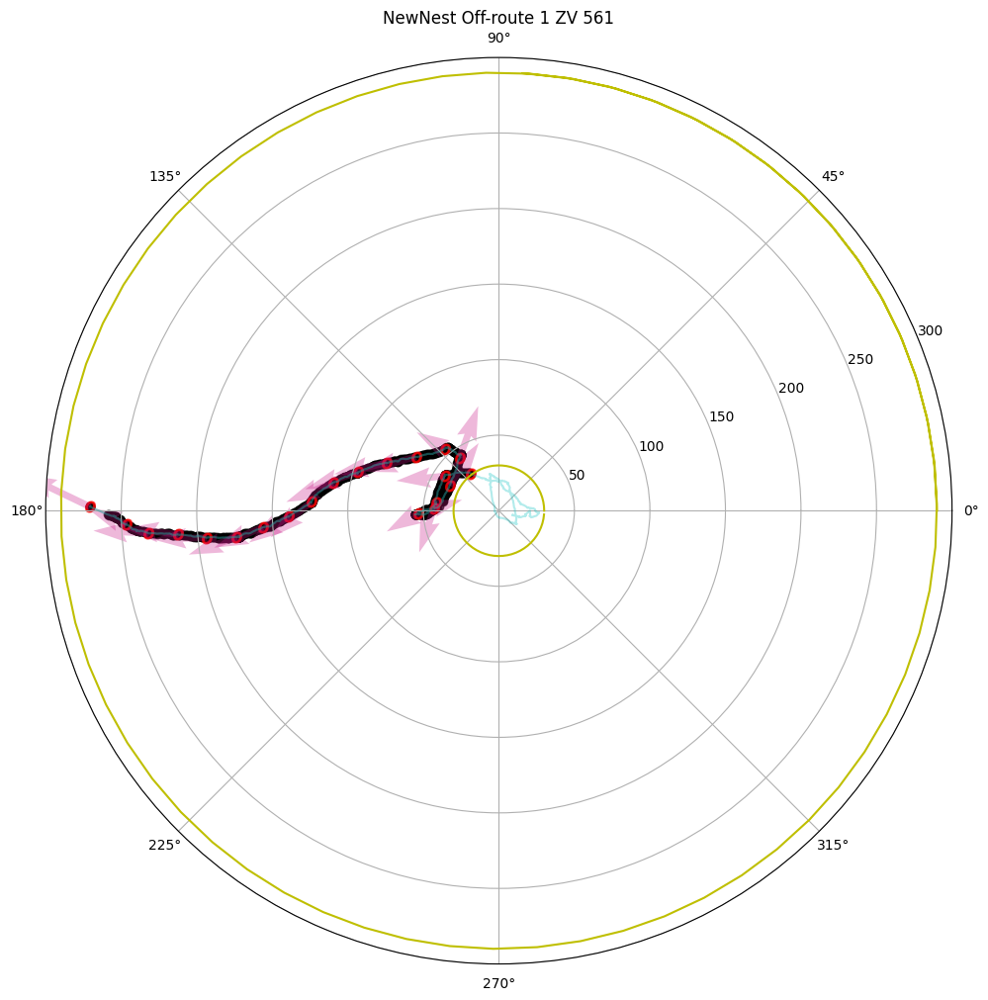

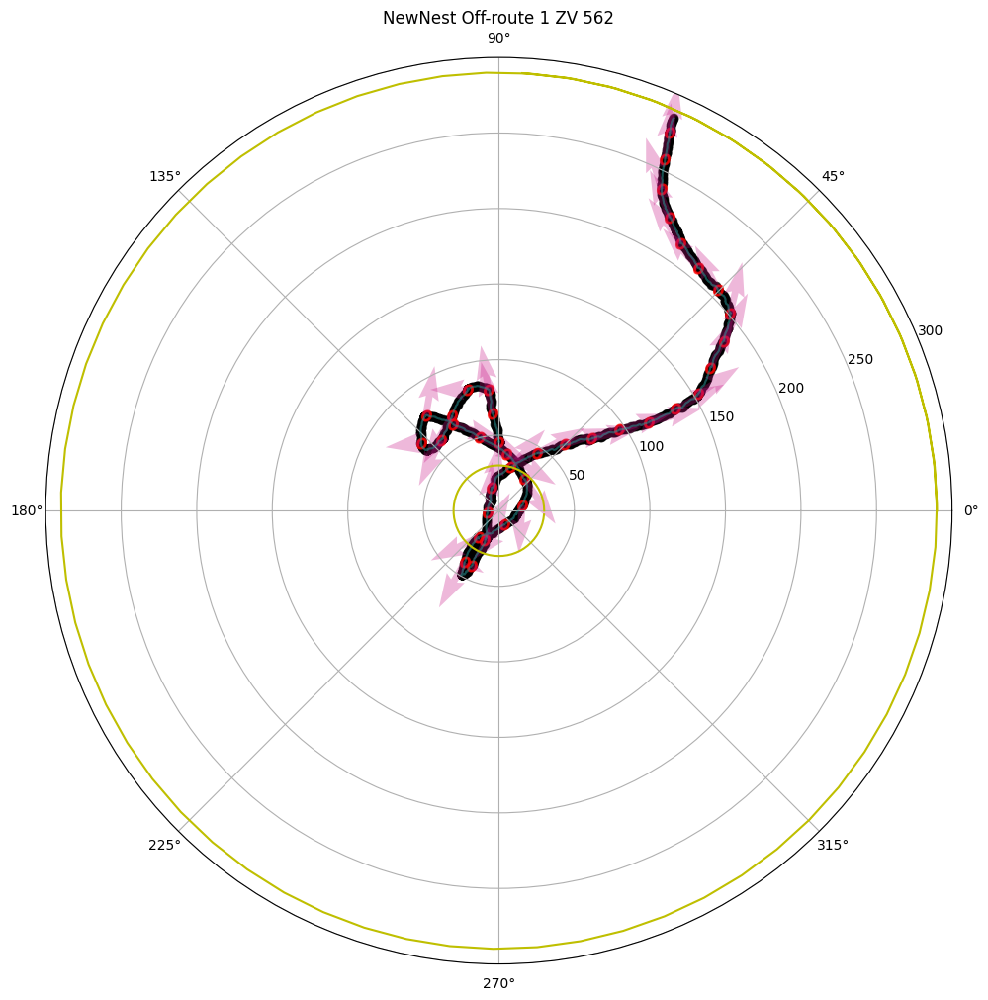

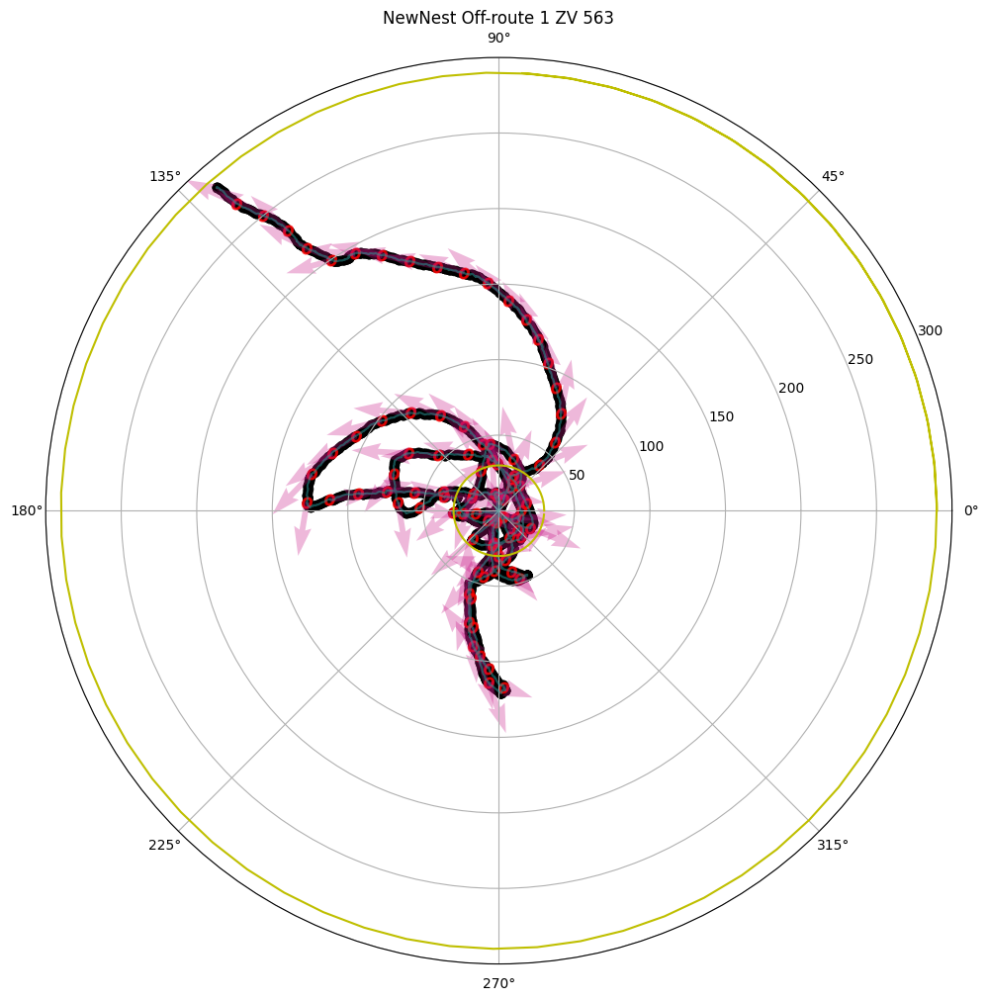

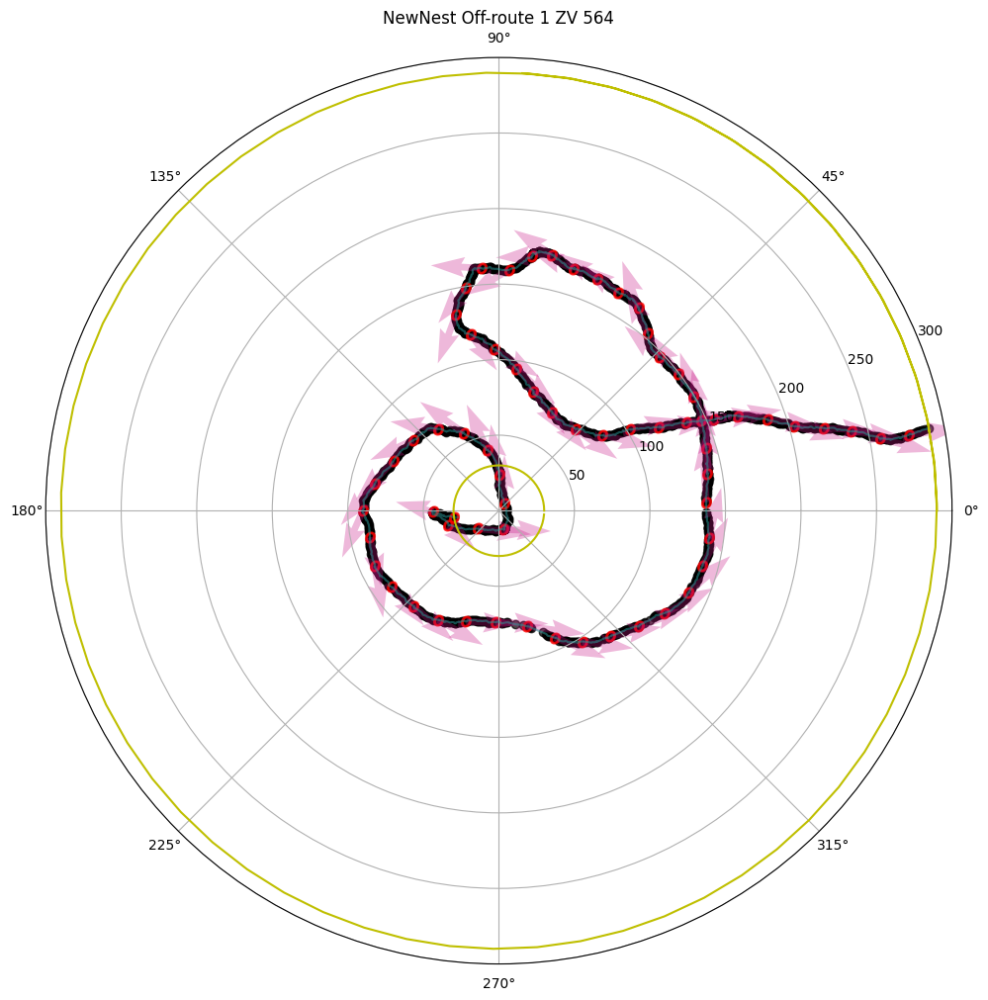

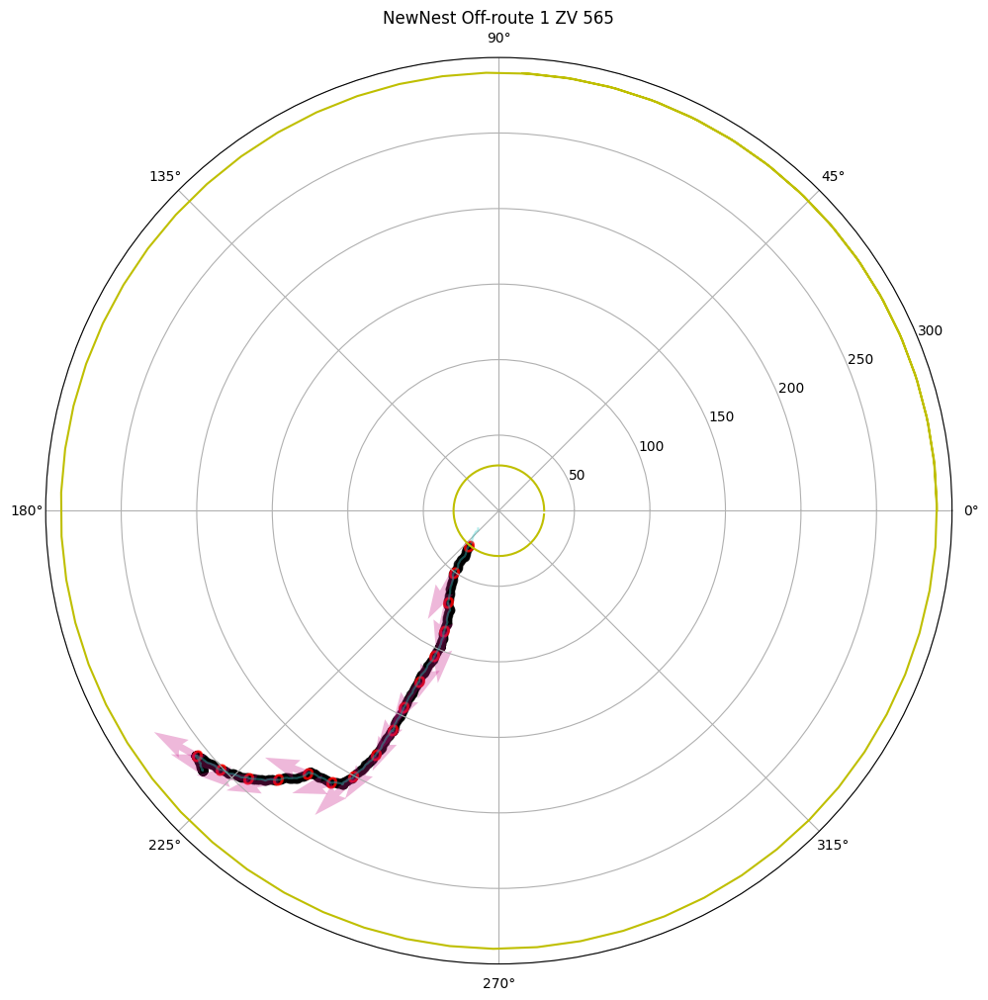

...

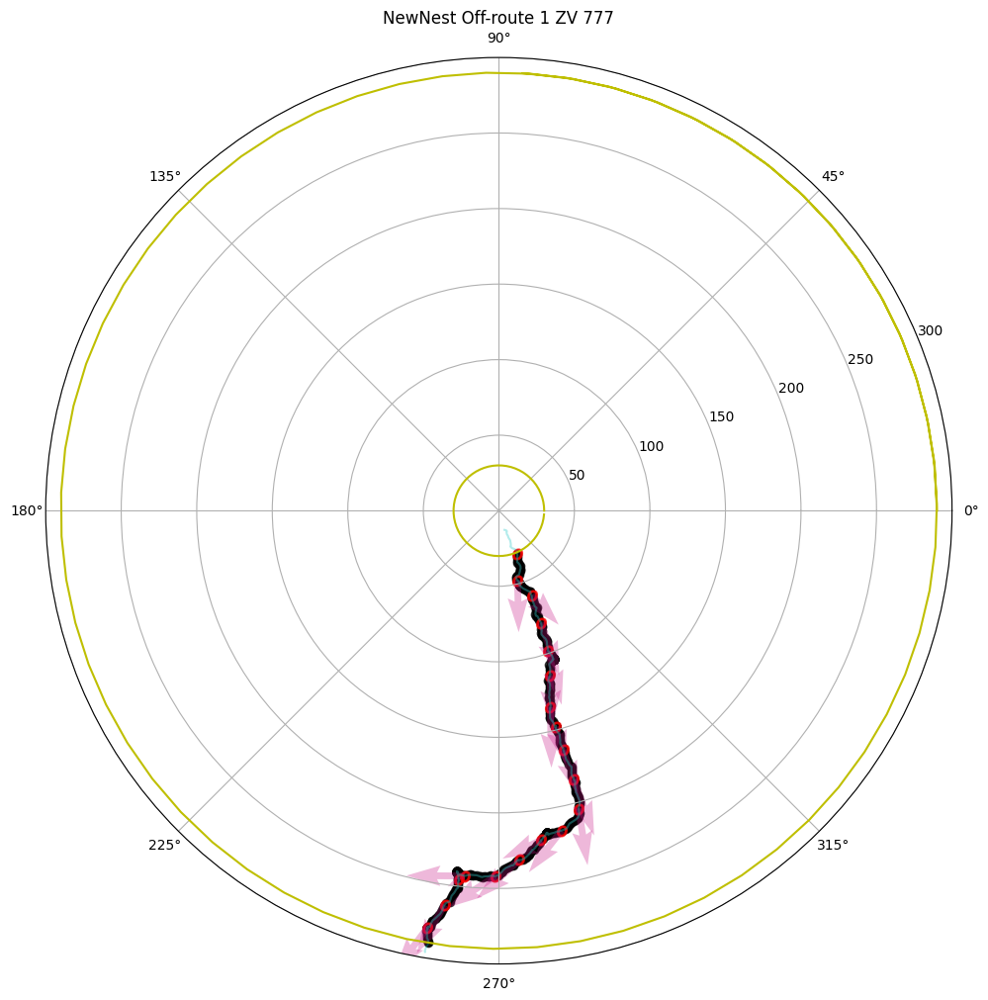

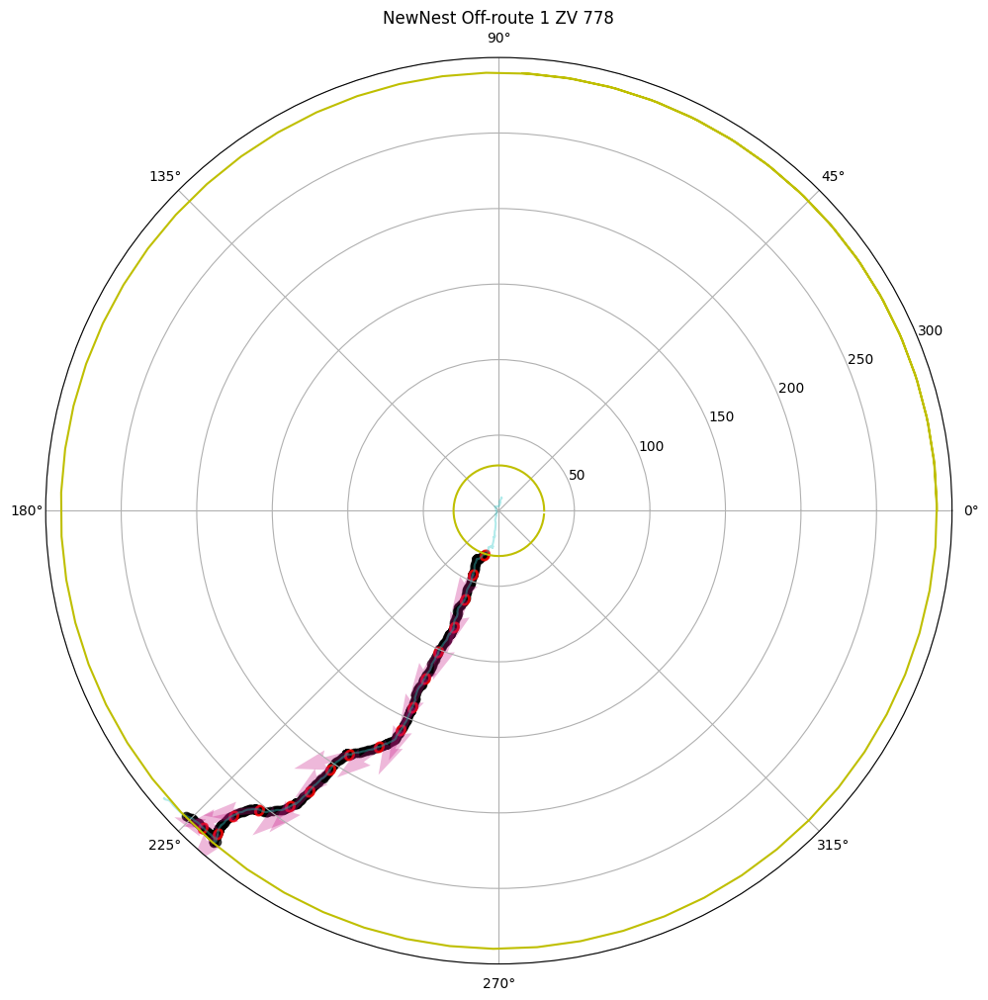

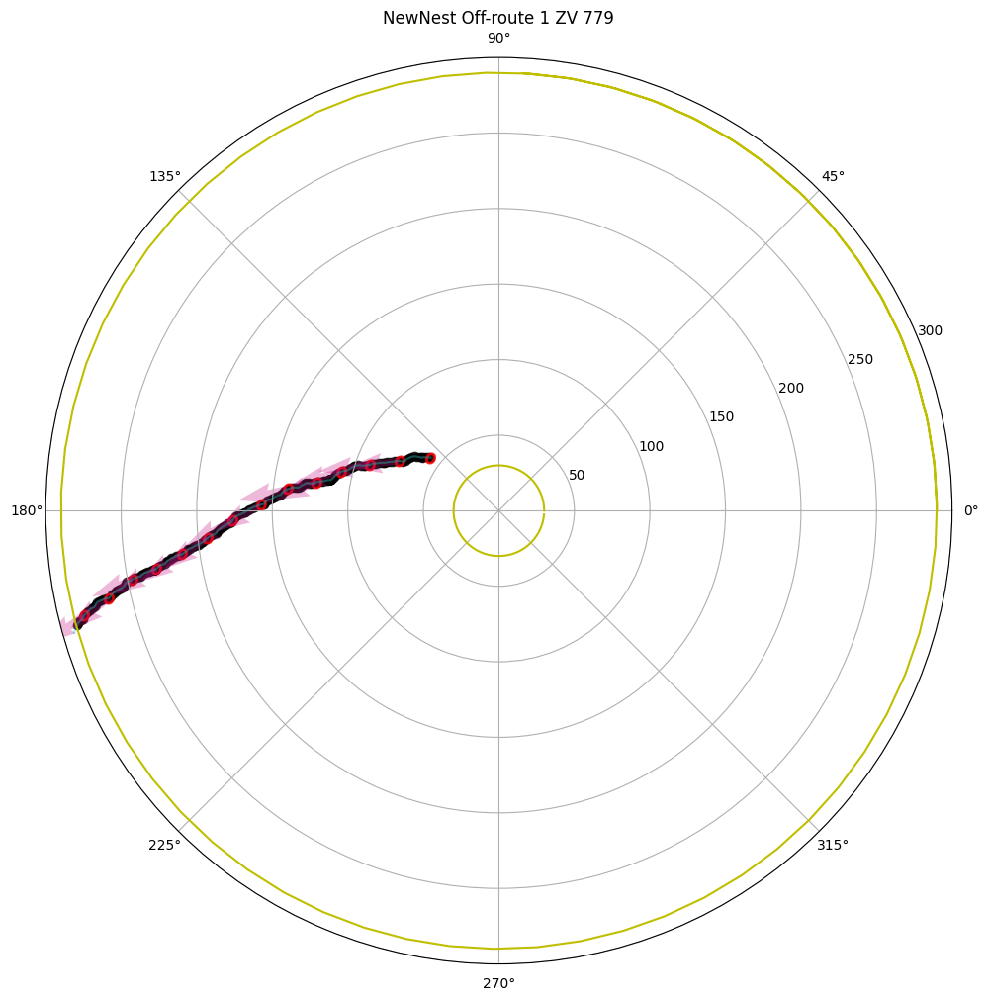

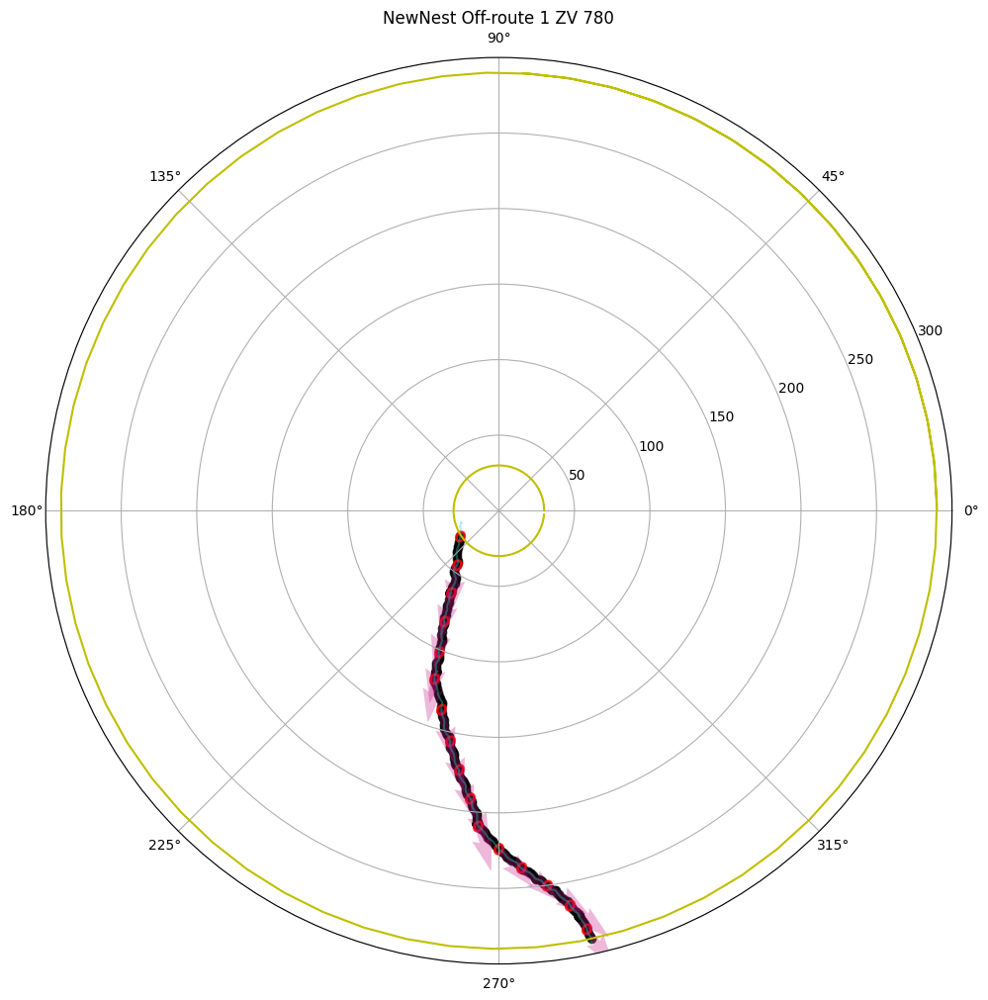

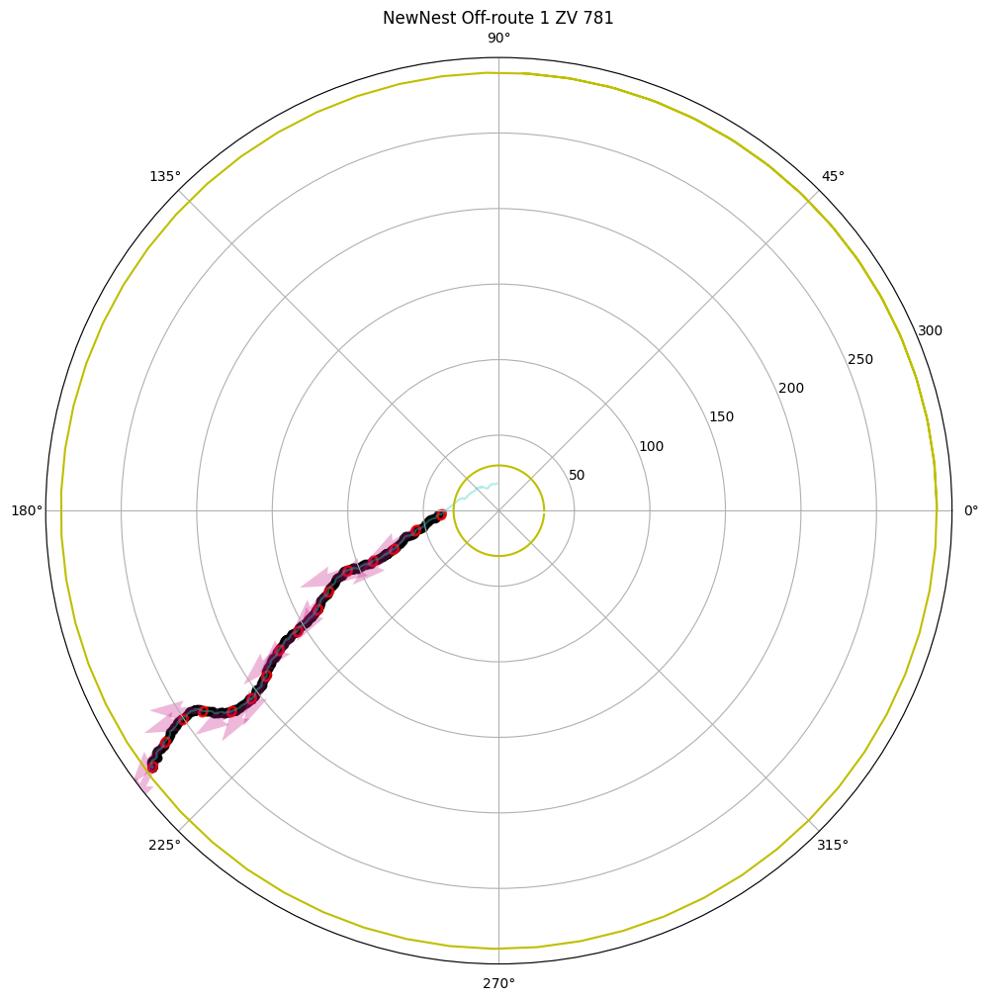

In [3]:
condition='Off-route 1 ZV'
nest = 'NewNest'#'Wigwam'
usedf = antTrackDF.copy()
print(nest, condition)

outdf_FP, outdf_Trim, outdf_TNG, fpchunkDict, trimchunkDict, trimNGchunkDict  = stats_condition(usedf, nest=nest, condition=condition, pplot=True,all=True)


In [1]:
outdf_Trim

NameError: name 'outdf_Trim' is not defined

In [4]:
#trimchunkDict698 = trimchunkDict[trimchunkDict['ID']=="652"]
##print(trimchunkDict698)
#print(np.rad2deg(1.694281))

#trimchunkDict698.to_csv("RealAntCheckMaths.csv")

In [5]:
outdf_Trim694 = outdf_Trim[outdf_Trim['ID']=="561"]

print(outdf_Trim694)
#outdf_Trim694.to_csv(f"outdf_Trim694_offr1.csv")

         index    Date   ID   frame           x          y     Nest  \
1041  520347.0  Aug-21  561  1041.0  -18.505686  24.670459  NewNest   
1042  520348.0  Aug-21  561  1042.0  -19.060997  24.895216  NewNest   
1043  520349.0  Aug-21  561  1043.0  -19.761495  25.377040  NewNest   
1044  520350.0  Aug-21  561  1044.0  -19.975536  25.325574  NewNest   
1045  520351.0  Aug-21  561  1045.0  -20.633601  25.238727  NewNest   
...        ...     ...  ...     ...         ...        ...      ...   
2242  521548.0  Aug-21  561  2296.0 -258.810138  -2.638484  NewNest   
2243  521549.0  Aug-21  561  2318.0 -270.499233   2.574145  NewNest   
2244  521550.0  Aug-21  561  2319.0 -270.467947   2.823613  NewNest   
2245  521551.0  Aug-21  561  2320.0 -270.557397   2.973074  NewNest   
2246  521552.0  Aug-21  561  2321.0 -270.464532   2.981080  NewNest   

           Condition    DI         rad  ...  deltaDist   accumDist     speed  \
1041  Off-route 1 ZV   1.0   30.839779  ...   1.218859         NaN 

In [13]:
outdf_TNG580 = outdf_TNG[outdf_TNG['ID']=="563"]
print(outdf_TNG580)#['dTheta'])

         index    Date   ID   frame           x           y     Nest  \
105   513787.0  Aug-21  563   105.0   -0.383159  -30.102511  NewNest   
106   513788.0  Aug-21  563   106.0   -0.619013  -30.125805  NewNest   
107   513789.0  Aug-21  563   107.0   -0.956306  -29.923998  NewNest   
108   513790.0  Aug-21  563   108.0   -1.037912  -30.002533  NewNest   
109   513791.0  Aug-21  563   109.0   -1.089767  -30.173185  NewNest   
...        ...     ...  ...     ...         ...         ...      ...   
5179  518861.0  Aug-21  563  5368.0 -186.686657  214.184193  NewNest   
5180  518862.0  Aug-21  563  5369.0 -186.672161  214.190525  NewNest   
5181  518863.0  Aug-21  563  5370.0 -186.549251  214.198325  NewNest   
5182  518864.0  Aug-21  563  5371.0 -186.803074  213.914384  NewNest   
5183  518865.0  Aug-21  563  5372.0 -186.712002  213.803105  NewNest   

           Condition   DI         rad  ...  deltaDist    accumDist     speed  \
105   Off-route 1 ZV  1.0   30.104950  ...   0.468933  

In [7]:
outdf_TNG580 = outdf_TNG[outdf_TNG['ID']=="563"]
print(outdf_TNG580)#['dTheta'])

#outdf_TNG580.to_csv("testing561.csv")

         index    Date   ID   frame           x           y     Nest  \
105   513787.0  Aug-21  563   105.0   -0.383159  -30.102511  NewNest   
106   513788.0  Aug-21  563   106.0   -0.619013  -30.125805  NewNest   
107   513789.0  Aug-21  563   107.0   -0.956306  -29.923998  NewNest   
108   513790.0  Aug-21  563   108.0   -1.037912  -30.002533  NewNest   
109   513791.0  Aug-21  563   109.0   -1.089767  -30.173185  NewNest   
...        ...     ...  ...     ...         ...         ...      ...   
5179  518861.0  Aug-21  563  5368.0 -186.686657  214.184193  NewNest   
5180  518862.0  Aug-21  563  5369.0 -186.672161  214.190525  NewNest   
5181  518863.0  Aug-21  563  5370.0 -186.549251  214.198325  NewNest   
5182  518864.0  Aug-21  563  5371.0 -186.803074  213.914384  NewNest   
5183  518865.0  Aug-21  563  5372.0 -186.712002  213.803105  NewNest   

           Condition   DI         rad  ...  deltaDist    accumDist     speed  \
105   Off-route 1 ZV  1.0   30.104950  ...   0.468933  

In [8]:
outdf_TNG580 = outdf_TNG[outdf_TNG['ID']=="563"]
print(outdf_TNG580['dTheta'])

105          NaN
106    -3.043149
107     2.602415
108    -2.375363
109    -1.865797
          ...   
5179    2.157446
5180    0.411818
5181    0.063375
5182   -2.300246
5183   -0.884932
Name: dTheta, Length: 5055, dtype: float64


In [9]:
outdf_TNG580 = outdf_TNG[outdf_TNG['ID']=="563"]
print(outdf_TNG580)

         index    Date   ID   frame           x           y     Nest  \
105   513787.0  Aug-21  563   105.0   -0.383159  -30.102511  NewNest   
106   513788.0  Aug-21  563   106.0   -0.619013  -30.125805  NewNest   
107   513789.0  Aug-21  563   107.0   -0.956306  -29.923998  NewNest   
108   513790.0  Aug-21  563   108.0   -1.037912  -30.002533  NewNest   
109   513791.0  Aug-21  563   109.0   -1.089767  -30.173185  NewNest   
...        ...     ...  ...     ...         ...         ...      ...   
5179  518861.0  Aug-21  563  5368.0 -186.686657  214.184193  NewNest   
5180  518862.0  Aug-21  563  5369.0 -186.672161  214.190525  NewNest   
5181  518863.0  Aug-21  563  5370.0 -186.549251  214.198325  NewNest   
5182  518864.0  Aug-21  563  5371.0 -186.803074  213.914384  NewNest   
5183  518865.0  Aug-21  563  5372.0 -186.712002  213.803105  NewNest   

           Condition   DI         rad  ...  deltaDist    accumDist     speed  \
105   Off-route 1 ZV  1.0   30.104950  ...   0.468933  

562,  580, 665, 694, 724, 725

In [10]:
selectedAnts = ["562",  "580", "665", "694", "724", "725"]

for i in selectedAnts:
    
    outdf_TNGSingle = outdf_TNG[outdf_TNG['ID']== i]
    outdf_TNGSingle.to_csv(f"nn_offr1_tNG_{i}.csv")

In [5]:
selectedAnts = ["562",  "580", "665", "694", "724", "725"]

for i in selectedAnts:
    
    outdf_TrimSingle = outdf_Trim[outdf_Trim['ID']== i]
    outdf_TrimSingle.to_csv(f"nn_offr1_trim_{i}.csv")

In [8]:
trimchunkDict580 = trimNGchunkDict[trimNGchunkDict['ID']=="562"] # 6 dcmlplaces
print("len 694", len(trimchunkDict580))
print(trimchunkDict580)
#trimchunkDict580.to_csv(f"outdf_TrimChunk694_offr1.csv")

KeyError: 'ID'

first chunk position is different! 

but! all headings are diff -> what is casusing differences? is it different function packages or us?

In [ ]:
trimNGchunkDict

In [ ]:
speeds = np.array(outdf_Trim_286['speed'])

print (f"len of speeds list : {len(speeds)}")
print(speeds[0:5])
print("")
print(speeds[-5:-1])

print("np mean : ",np.mean(speeds[1:]))

from statistics import mean
print("statistics mean : ",mean(speeds[1:]))

In [ ]:
speeds = np.array(outdf_TNG_286['speed'])

print (f"len of speeds list : {len(speeds)}")
print(speeds[0:5])
print("")
print(speeds[-5:-1])

print("np mean : ",np.mean(speeds[1:]))

from statistics import mean
print("statistics mean : ",mean(speeds[1:]))

In [ ]:
list(outdf_TNG_286)

In [ ]:
outdf_TNG_286['trimNG_circR']

In [ ]:
outdf_TNG_286['dTheta']

In [ ]:
list(trimNGchunkDict)

In [ ]:
trimNGchunkDict

In [ ]:
outdf_FP
outdf_Trim
outdf_TNG
fpchunkDict
trimchunkDict
trimNGchunkDict

In [ ]:
outdf_Trim